# ĐỀ TÀI: PHÂN TÍCH VÀ DỰ ĐOÁN SỨC KHỎE TÂM THẦN Ở THANH THIẾU NIÊN MOROCCO

Nghiên cứu sử dụng dữ liệu khảo sát sức khỏe học sinh thuộc bộ Global School-based Student Health Survey (GSHS) tại Morocco để khám phá tình trạng sức khỏe tâm thần và xây dựng mô hình học máy dự đoán khả năng học sinh từng nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua.

Các mục tiêu cụ thể:

- Khám phá đặc điểm nhân khẩu học của học sinh thông qua nhóm tuổi và giới tính.

- Phân tích tình trạng cô đơn, lo lắng ảnh hưởng đến giấc ngủ, tình trạng bị bắt nạt, bạo lực, chấn thương và số lượng bạn thân.

- Phân tích tỷ lệ học sinh trả lời Có/Không đối với biến mục tiêu Q24.

- Xây dựng và đánh giá các mô hình Machine Learning và Deep Learning.

- So sánh hiệu quả các mô hình thông qua Accuracy, Precision, Recall, F1-score và Confusion Matrix.

- Xác định mô hình phù hợp dựa trên mục tiêu phát hiện nhóm học sinh trả lời Có ở câu hỏi Q24.

Dữ liệu nghiên cứu thuộc bộ khảo sát Global School-based Student Health Survey (GSHS), được sử dụng để khảo sát các hành vi và yếu tố liên quan đến sức khỏe của học sinh trong môi trường trường học.

- Quốc gia: Morocco.
- Năm khảo sát: 2016 (theo tên tệp dữ liệu `2016MAR (National).csv`).
- Dữ liệu: `data/2016MAR (National).csv`.
- Tài liệu quy ước mã: `data/QuyUocMorocco.docx`.

Biến mục tiêu: Q24 — Trong 12 tháng qua, bạn có bao giờ nghiêm túc nghĩ đến việc tự tử không?

Biến đầu vào: Q1, Q2, Q15, Q16, Q17, Q20, Q21, Q22, Q23 và Q27.

Quy ước biến mục tiêu Q24 (theo `QuyUocMorocco.docx`)

- Mã 1: Đúng/Có — học sinh nghiêm túc nghĩ đến việc tự tử.
- Mã 2: Không — học sinh không nghiêm túc nghĩ đến việc tự tử.
- Sysmiss: Giá trị thiếu theo bảng quy ước khảo sát.

---
# PHẦN 1. TỔNG QUAN VỀ DỮ LIỆU

### 1. Import thư viện

In [19]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Đã import thư viện thành công.")

Đã import thư viện thành công.


### 2. Đọc file CSV

In [27]:
CSV_CANDIDATES = [
    Path("data/2016MAR (National).csv"),
    Path("../data/2016MAR (National).csv"),
]
CSV_PATH = next((path for path in CSV_CANDIDATES if path.exists()), None)

if CSV_PATH is None:
    checked_paths = ", ".join(str(path.resolve()) for path in CSV_CANDIDATES)
    raise FileNotFoundError(
        "Không tìm thấy file 2016MAR (National).csv. "
        f"Đã kiểm tra: {checked_paths}"
    )

df = pd.read_csv(CSV_PATH, low_memory=False)
data = df.copy()
print("Đọc dữ liệu thành công:", CSV_PATH.resolve())
print("Số dòng:", data.shape[0])
print("Số cột:", data.shape[1])

Đọc dữ liệu thành công: D:\BaoCaoPython\Python_report\data\2016MAR (National).csv
Số dòng: 6745
Số cột: 141


Kiểm tra 5 dòng đầu

In [21]:
# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Kích thước dữ liệu:", df.shape)
print("Tổng số dòng:", len(df))
print("Tổng số cột:", len(df.columns))

# Danh sách tên cột
print("\nDanh sách tên cột:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27,Q28,Q29,Q30,Q31,Q32,Q33,Q34,Q35,Q36,Q37,Q38,Q39,Q40,Q41,Q42,Q43,Q44,Q45,Q46,Q47,Q48,Q49,Q50,...,QN39,QN40,QN41,QN42,QN43,QN44,QN45,QN46,QN47,QN48,QN49,QN50,QN51,QN52,QN53,QN54,QN55,QN56,QN57,QN58,qnunwtg,qnowtg,qnobeseg,qnfrlg,qnfr1g,qnfr2g,qnfr3g,qnveglg,qnveg1g,qnveg2g,qnveg3g,qnsodalg,qnsoda1g,qnsoda2g,qnsoda3g,qnff1g,qnff2g,qnff3g,qnc2g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g,weight,stratum,psu
0,5.0,1.0,1.0,1.60,46.0,1.0,1.0,3.0,1.0,1.0,3.0,5.0,2.0,3.0,7.0,NaN,4.0,NaN,7.0,4.0,2.0,NaN,2.0,NaN,NaN,NaN,NaN,5.0,2.0,4.0,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,1.0,5.0,3.0,NaN,NaN,NaN,NaN,NaN,1.0,5.0,...,NaN,1.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,2.0,1.0,NaN,2.0,1.0,NaN,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,1.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,184.1726,201601003,6
1,3.0,2.0,1.0,1.60,50.0,1.0,3.0,4.0,3.0,2.0,4.0,5.0,5.0,5.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,3.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,1.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,184.7697,201601003,6
2,3.0,1.0,1.0,1.40,34.0,4.0,3.0,2.0,NaN,1.0,1.0,5.0,5.0,5.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,8.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,184.1726,201601003,6
3,4.0,1.0,1.0,1.70,54.0,4.0,1.0,3.0,3.0,7.0,1.0,2.0,NaN,2.0,6.0,6.0,5.0,NaN,4.0,3.0,2.0,4.0,4.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,1.0,3.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,...,NaN,1.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,NaN,NaN,2.0,2.0,NaN,NaN,184.1726,201601003,6
4,2.0,2.0,1.0,1.45,40.0,1.0,5.0,6.0,3.0,1.0,6.0,5.0,5.0,5.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,3.0,1.0,2.0,2.0,1.0,4.0,NaN,1.0,1.0,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,3.0,1.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,184.7697,201601003,6


Kích thước dữ liệu: (6745, 141)
Tổng số dòng: 6745
Tổng số cột: 141

Danh sách tên cột:
1. Q1
2. Q2
3. Q3
4. Q4
5. Q5
6. Q6
7. Q7
8. Q8
9. Q9
10. Q10
11. Q11
12. Q12
13. Q13
14. Q14
15. Q15
16. Q16
17. Q17
18. Q18
19. Q19
20. Q20
21. Q21
22. Q22
23. Q23
24. Q24
25. Q25
26. Q26
27. Q27
28. Q28
29. Q29
30. Q30
31. Q31
32. Q32
33. Q33
34. Q34
35. Q35
36. Q36
37. Q37
38. Q38
39. Q39
40. Q40
41. Q41
42. Q42
43. Q43
44. Q44
45. Q45
46. Q46
47. Q47
48. Q48
49. Q49
50. Q50
51. Q51
52. Q52
53. Q53
54. Q54
55. Q55
56. Q56
57. Q57
58. Q58
59. QN6
60. QN7
61. QN8
62. QN9
63. QN10
64. QN11
65. QN12
66. QN13
67. QN14
68. QN15
69. QN16
70. QN17
71. QN18
72. QN19
73. QN20
74. QN21
75. QN22
76. QN23
77. QN24
78. QN25
79. QN26
80. QN27
81. QN28
82. QN29
83. QN30
84. QN31
85. QN32
86. QN33
87. QN34
88. QN35
89. QN36
90. QN37
91. QN38
92. QN39
93. QN40
94. QN41
95. QN42
96. QN43
97. QN44
98. QN45
99. QN46
100. QN47
101. QN48
102. QN49
103. QN50
104. QN51
105. QN52
106. QN53
107. QN54
108. QN55
109. QN56
1

### 3. Kiểm tra kiểu dữ liệu và thống kê mô tả

In [22]:
# Kiểm tra kiểu dữ liệu
print("Thông tin dữ liệu:")
df.info()

# Bảng kiểu dữ liệu
dtype_table = pd.DataFrame({
    "Tên cột": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị khác nhau": [
        df[col].nunique(dropna=True) for col in df.columns
    ],
    "Số lượng thiếu": [
        df[col].isna().sum() for col in df.columns
    ]
})

display(dtype_table)

# Thống kê mô tả các cột số
print("Thống kê mô tả dữ liệu số:")
display(df.describe().T)

# Thống kê mô tả tất cả các cột
print("Thống kê mô tả tổng quát:")
display(df.describe(include="all").T)

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Columns: 141 entries, Q1 to psu
dtypes: float64(139), int64(2)
memory usage: 7.3 MB


,Tên cột,Kiểu dữ liệu,Số giá trị khác nhau,Số lượng thiếu
0,Q1,float64,8,112
1,Q2,float64,2,172
2,Q3,float64,6,200
3,Q4,float64,73,697
4,Q5,float64,84,697
5,Q6,float64,5,206
6,Q7,float64,7,128
7,Q8,float64,7,139
8,Q9,float64,7,95
9,Q10,float64,8,63


Thống kê mô tả dữ liệu số:


,count,mean,std,min,25%,50%,75%,max
Q1,6633.0,4.829790e+00,1.878905,1.000000e+00,3.000000e+00,5.000000e+00,6.000000e+00,8.000000e+00
Q2,6573.0,1.469344e+00,0.499097,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
Q3,6545.0,2.961956e+00,1.640689,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00
Q4,6048.0,1.604726e+00,0.116182,1.140000e+00,1.530000e+00,1.600000e+00,1.680000e+00,2.000000e+00
Q5,6048.0,5.094312e+01,11.596536,2.400000e+01,4.300000e+01,5.000000e+01,5.800000e+01,1.500000e+02
Q6,6539.0,1.716317e+00,1.132596,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00
Q7,6617.0,3.731600e+00,1.797037,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,7.000000e+00
Q8,6606.0,3.920224e+00,1.741638,1.000000e+00,3.000000e+00,3.000000e+00,5.000000e+00,7.000000e+00
Q9,6650.0,2.376391e+00,1.606166,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,7.000000e+00
Q10,6682.0,2.728075e+00,2.069186,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,8.000000e+00


Thống kê mô tả tổng quát:


,count,mean,std,min,25%,50%,75%,max
Q1,6633.0,4.829790e+00,1.878905,1.000000e+00,3.000000e+00,5.000000e+00,6.000000e+00,8.000000e+00
Q2,6573.0,1.469344e+00,0.499097,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
Q3,6545.0,2.961956e+00,1.640689,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00
Q4,6048.0,1.604726e+00,0.116182,1.140000e+00,1.530000e+00,1.600000e+00,1.680000e+00,2.000000e+00
Q5,6048.0,5.094312e+01,11.596536,2.400000e+01,4.300000e+01,5.000000e+01,5.800000e+01,1.500000e+02
Q6,6539.0,1.716317e+00,1.132596,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00
Q7,6617.0,3.731600e+00,1.797037,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,7.000000e+00
Q8,6606.0,3.920224e+00,1.741638,1.000000e+00,3.000000e+00,3.000000e+00,5.000000e+00,7.000000e+00
Q9,6650.0,2.376391e+00,1.606166,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,7.000000e+00
Q10,6682.0,2.728075e+00,2.069186,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,8.000000e+00


---
# PHẦN 2. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

Chuẩn hóa tên cột câu hỏi

In [23]:
def find_question_column(data, question_number):
    q_col = f"Q{question_number}"
    qn_col = f"QN{question_number}"

    # Chuẩn hóa tên cột để không phân biệt chữ hoa/chữ thường
    column_map = {
        re.sub(r"[^a-z0-9]", "", str(col).lower()): col
        for col in data.columns
    }

    q_key = q_col.lower()
    qn_key = qn_col.lower()

    if q_key in column_map:
        return column_map[q_key]

    if qn_key in column_map:
        return column_map[qn_key]

    raise KeyError(
        f"Không tìm thấy cột Q{question_number} hoặc QN{question_number}. "
        f"Các cột hiện có: {list(data.columns)}"
    )


# Kiểm tra lại các biến
questions_to_check = [1, 2, 15, 16, 17, 20, 21, 22, 23, 24, 27]

for q in questions_to_check:
    try:
        print(f"Q{q}: {find_question_column(df, q)}")
    except KeyError as error:
        print(error)

Q1: Q1
Q2: Q2
Q15: Q15
Q16: Q16
Q17: Q17
Q20: Q20
Q21: Q21
Q22: Q22
Q23: Q23
Q24: Q24
Q27: Q27


### 2.1 Kiểm tra dữ liệu thiếu 

In [24]:
missing_summary = pd.DataFrame({
    "So_luong_thieu": df.isna().sum(),
    "Ty_le_thieu_%": (df.isna().mean() * 100).round(2),
    "So_luong_hop_le": df.notna().sum()
})

missing_summary = missing_summary.sort_values(
    "Ty_le_thieu_%",
    ascending=False
)

display(missing_summary)

,So_luong_thieu,Ty_le_thieu_%,So_luong_hop_le
QN18,6745,100.00,0
Q46,6745,100.00,0
Q47,6745,100.00,0
Q48,6745,100.00,0
Q38,6745,100.00,0
Q37,6745,100.00,0
Q36,6745,100.00,0
Q35,6745,100.00,0
Q34,6745,100.00,0
Q45,6745,100.00,0


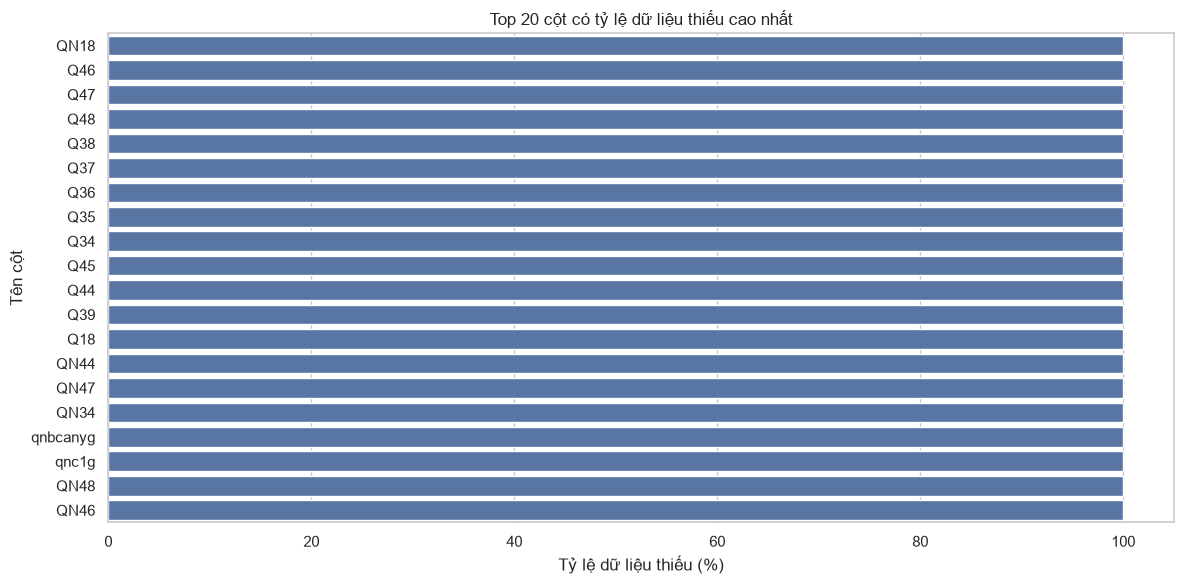

In [25]:
missing_plot = missing_summary[
    missing_summary["So_luong_thieu"] > 0
].head(20)

if not missing_plot.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=missing_plot["Ty_le_thieu_%"],
        y=missing_plot.index
    )

    plt.title("Top 20 cột có tỷ lệ dữ liệu thiếu cao nhất")
    plt.xlabel("Tỷ lệ dữ liệu thiếu (%)")
    plt.ylabel("Tên cột")
    plt.tight_layout()
    plt.show()
else:
    print("Không phát hiện NaN trong dữ liệu.")

Kiểm tra dữ liệu thiếu của các biến đầu vào

In [29]:
import pandas as pd
import numpy as np

input_columns = [
    "Q1", "Q2", "Q15", "Q16", "Q17",
    "Q20", "Q21", "Q22", "Q23", "Q27"
]
target_column = "Q24"

# Thống kê dữ liệu thiếu
columns = input_columns + [target_column]

missing_summary = pd.DataFrame({
    "Số lượng thiếu": data[columns].isna().sum(),
    "Tỷ lệ thiếu (%)": (
        data[columns].isna().mean() * 100
    ).round(2),
    "Số lượng hợp lệ": data[columns].notna().sum(),
    "Tổng số lượng": len(data)
})

display(missing_summary)

,Số lượng thiếu,Tỷ lệ thiếu (%),Số lượng hợp lệ,Tổng số lượng
Q1,112,1.66,6633,6745
Q2,172,2.55,6573,6745
Q15,77,1.14,6668,6745
Q16,119,1.76,6626,6745
Q17,553,8.20,6192,6745
Q20,410,6.08,6335,6745
Q21,438,6.49,6307,6745
Q22,188,2.79,6557,6745
Q23,85,1.26,6660,6745
Q27,207,3.07,6538,6745


### 💡 Nhận xét ban đầu về dữ liệu khuyết thiếu:
Kết quả thống kê cho thấy các biến được lựa chọn phục vụ phân tích có tỷ lệ dữ liệu khuyết thiếu khác nhau, dao động từ 1,14% đến 8,20%.

- Q17 có tỷ lệ khuyết thiếu cao nhất, đạt 8,20% (553 giá trị thiếu). Đây là biến cần được chú ý khi tiền xử lý dữ liệu.

- Q20 và Q21 lần lượt có tỷ lệ khuyết thiếu là 6,08% và 6,49%, cho thấy một số lượng đáng kể câu trả lời chưa đầy đủ.

- Q24, biến mục tiêu dự đoán trong nghiên cứu, có 318 giá trị thiếu, chiếm 4,71%. Những bản ghi này cần được xem xét riêng; không nên tự động gán thành câu trả lời “Không”.

- Các biến Q1, Q2, Q15, Q16, Q22, Q23 và Q27 có tỷ lệ khuyết thiếu tương đối thấp, từ 1,14% đến 3,07%.

Kết luận: Nhìn chung, các biến được thống kê có tỷ lệ dữ liệu khuyết thiếu dưới 10%, cho thấy mức độ thiếu dữ liệu tương đối thấp. Tuy nhiên, cần lựa chọn phương pháp xử lý phù hợp với từng biến và ý nghĩa câu trả lời trong codebook. Đặc biệt, với Q24, nên loại các bản ghi không có nhãn mục tiêu hợp lệ khỏi quá trình huấn luyện và đánh giá có giám sát. Các biến đầu vào còn thiếu có thể được xử lý bằng phương pháp điền giá trị phù hợp hoặc loại bỏ bản ghi nếu có cơ sở hợp lý.

### 2.2. Phân tích độ tuổi, giới tính 

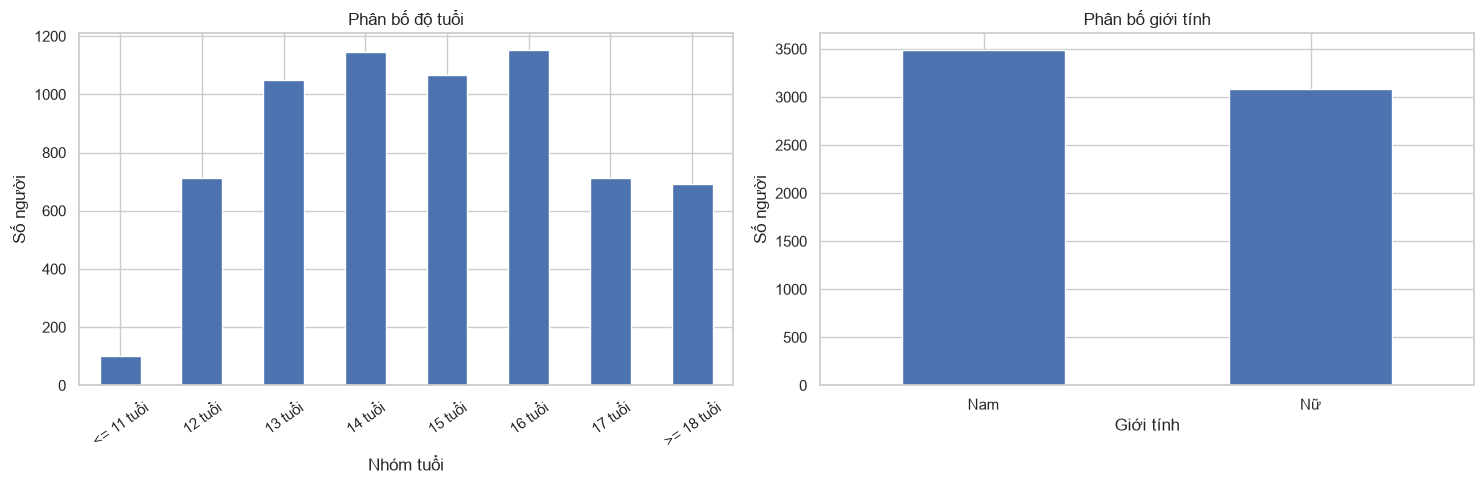

Bảng tần số độ tuổi:


,Số người
<= 11 tuổi,100
12 tuổi,713
13 tuổi,1050
14 tuổi,1147
15 tuổi,1065
16 tuổi,1152
17 tuổi,713
>= 18 tuổi,693


Bảng tần số giới tính:


,Số người
Nam,3488
Nữ,3085


In [30]:
age_col = find_question_column(df, 1)
sex_col = find_question_column(df, 2)

age_labels = {
    1: "<= 11 tuổi",
    2: "12 tuổi",
    3: "13 tuổi",
    4: "14 tuổi",
    5: "15 tuổi",
    6: "16 tuổi",
    7: "17 tuổi",
    8: ">= 18 tuổi"
}

sex_labels = {
    1: "Nam",
    2: "Nữ"
}

age = pd.to_numeric(df[age_col], errors="coerce")
sex = pd.to_numeric(df[sex_col], errors="coerce")

age_counts = age.value_counts().sort_index()
age_counts.index = [
    age_labels.get(int(value), f"Mã {value}")
    for value in age_counts.index
]

sex_counts = sex.value_counts().sort_index()
sex_counts.index = [
    sex_labels.get(int(value), f"Mã {value}")
    for value in sex_counts.index
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

age_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Phân bố độ tuổi")
axes[0].set_xlabel("Nhóm tuổi")
axes[0].set_ylabel("Số người")
axes[0].tick_params(axis="x", rotation=35)

sex_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Phân bố giới tính")
axes[1].set_xlabel("Giới tính")
axes[1].set_ylabel("Số người")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Bảng tần số độ tuổi:")
display(age_counts.rename("Số người").to_frame())

print("Bảng tần số giới tính:")
display(sex_counts.rename("Số người").to_frame())

### 2.3. Phân tích cảm giác cô đơn và lo lắng ảnh hưởng đến giấc ngủ

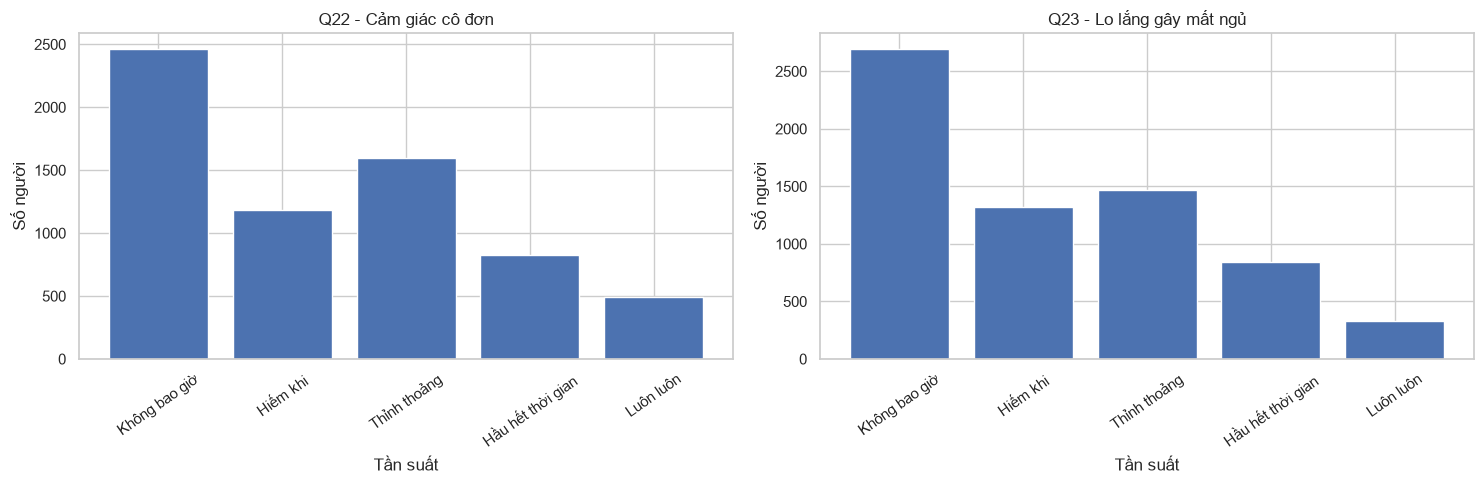

Q22 - Cảm giác cô đơn:


,Nhãn,Số người,Tỷ lệ trong câu trả lời hợp lệ (%)
0,Không bao giờ,2464,37.58
1,Hiếm khi,1182,18.03
2,Thỉnh thoảng,1594,24.31
3,Hầu hết thời gian,825,12.58
4,Luôn luôn,492,7.50


Q23 - Lo lắng gây mất ngủ:


,Nhãn,Số người,Tỷ lệ trong câu trả lời hợp lệ (%)
0,Không bao giờ,2695,40.47
1,Hiếm khi,1324,19.88
2,Thỉnh thoảng,1470,22.07
3,Hầu hết thời gian,841,12.63
4,Luôn luôn,330,4.95


In [32]:
lonely_col = find_question_column(df, 22)
worry_col = find_question_column(df, 23)

frequency_labels = {
    1: "Không bao giờ",
    2: "Hiếm khi",
    3: "Thỉnh thoảng",
    4: "Hầu hết thời gian",
    5: "Luôn luôn"
}

lonely = pd.to_numeric(df[lonely_col], errors="coerce")
worry = pd.to_numeric(df[worry_col], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, series, title in [
    (axes[0], lonely, "Q22 - Cảm giác cô đơn"),
    (axes[1], worry, "Q23 - Lo lắng gây mất ngủ")
]:
    counts = series[series.isin([1, 2, 3, 4, 5])].value_counts()
    counts = counts.reindex([1, 2, 3, 4, 5], fill_value=0)
    labels = [frequency_labels[i] for i in counts.index]

    ax.bar(labels, counts.values)
    ax.set_title(title)
    ax.set_xlabel("Tần suất")
    ax.set_ylabel("Số người")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

def frequency_table(series, labels):
    valid = series[series.isin(labels.keys())]
    result = valid.value_counts().reindex(labels.keys(), fill_value=0)

    table = pd.DataFrame({
        "Nhãn": [labels[k] for k in result.index],
        "Số người": result.values,
        "Tỷ lệ trong câu trả lời hợp lệ (%)":
            (result.values / max(len(valid), 1) * 100).round(2)
    })

    return table

print("Q22 - Cảm giác cô đơn:")
display(frequency_table(lonely, frequency_labels))

print("Q23 - Lo lắng gây mất ngủ:")
display(frequency_table(worry, frequency_labels))

### 2.4. Phân tích số lượng bạn thân

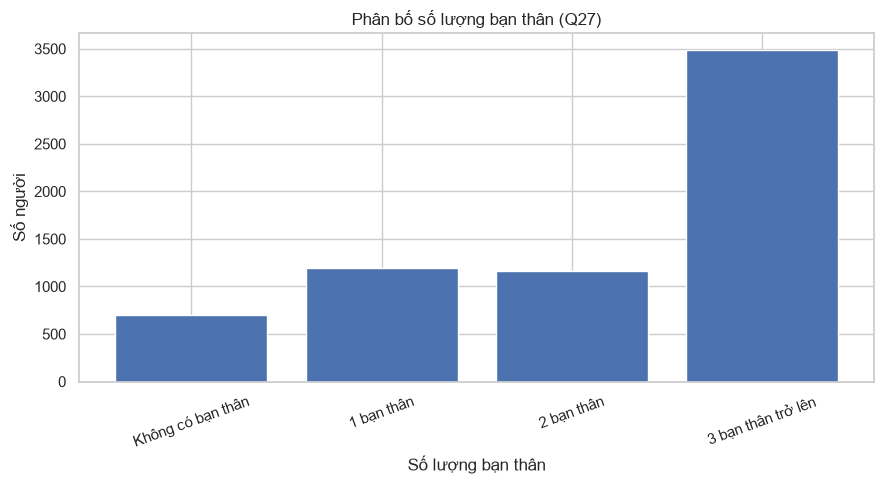

,Nhóm bạn thân,Số người,Tỷ lệ trong câu trả lời hợp lệ (%)
0,Không có bạn thân,698,10.68
1,1 bạn thân,1189,18.19
2,2 bạn thân,1163,17.79
3,3 bạn thân trở lên,3488,53.35


In [33]:
friends_col = find_question_column(df, 27)
friends = pd.to_numeric(df[friends_col], errors="coerce")

friends_labels = {
    1: "Không có bạn thân",
    2: "1 bạn thân",
    3: "2 bạn thân",
    4: "3 bạn thân trở lên"
}

valid_friends = friends[friends.isin(friends_labels.keys())]
friends_counts = (
    valid_friends.value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
)

plt.figure(figsize=(9, 5))
plt.bar(
    [friends_labels[k] for k in friends_counts.index],
    friends_counts.values
)
plt.title("Phân bố số lượng bạn thân (Q27)")
plt.xlabel("Số lượng bạn thân")
plt.ylabel("Số người")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

friends_table = pd.DataFrame({
    "Nhóm bạn thân": [friends_labels[k] for k in friends_counts.index],
    "Số người": friends_counts.values,
    "Tỷ lệ trong câu trả lời hợp lệ (%)":
        (friends_counts.values / max(len(valid_friends), 1) * 100).round(2)
})

display(friends_table)

### 2.5. Phân bố biến mục tiêu Q24

,Trả lời,Số người,Tỷ lệ trong câu trả lời hợp lệ (%)
0,Có,1031,16.04
1,Không,5396,83.96


Tổng số dòng trong dữ liệu: 6745
Số câu trả lời Q24 hợp lệ: 6427
Số dòng Q24 thiếu hoặc không thuộc mã 1/2: 318
Tỷ lệ thiếu/không hợp lệ Q24: 4.71%


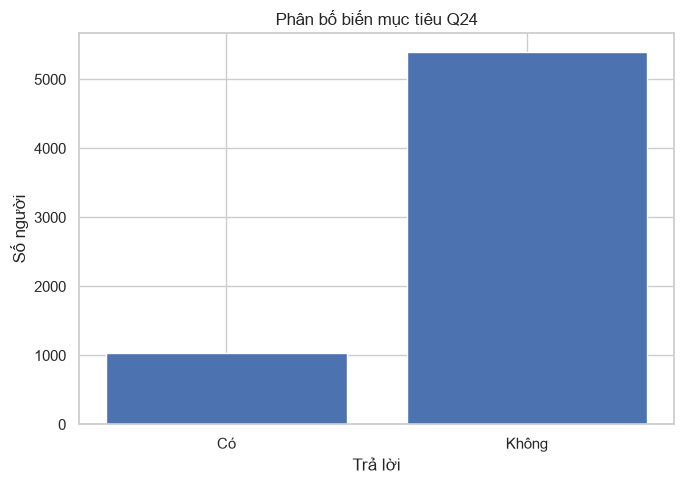

In [34]:
target_col = find_question_column(df, 24)
target_raw = pd.to_numeric(df[target_col], errors="coerce")

target_labels = {
    1: "Có",
    2: "Không"
}

valid_target = target_raw[target_raw.isin([1, 2])]
target_counts = (
    valid_target.value_counts()
    .reindex([1, 2], fill_value=0)
)

target_missing = int((~target_raw.isin([1, 2])).sum())
target_valid_n = int(len(valid_target))

target_table = pd.DataFrame({
    "Trả lời": ["Có", "Không"],
    "Số người": [target_counts.loc[1], target_counts.loc[2]],
    "Tỷ lệ trong câu trả lời hợp lệ (%)": [
        round(target_counts.loc[1] / max(target_valid_n, 1) * 100, 2),
        round(target_counts.loc[2] / max(target_valid_n, 1) * 100, 2)
    ]
})

display(target_table)

print(f"Tổng số dòng trong dữ liệu: {len(df)}")
print(f"Số câu trả lời Q24 hợp lệ: {target_valid_n}")
print(f"Số dòng Q24 thiếu hoặc không thuộc mã 1/2: {target_missing}")
print(f"Tỷ lệ thiếu/không hợp lệ Q24: {target_missing / max(len(df), 1) * 100:.2f}%")

plt.figure(figsize=(7, 5))
plt.bar(
    ["Có", "Không"],
    [target_counts.loc[1], target_counts.loc[2]]
)
plt.title("Phân bố biến mục tiêu Q24")
plt.xlabel("Trả lời")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

### 2.6. Phân tích tỷ lệ trả lời "Có" theo nhóm tuổi và giới tính

,age_label,So_nguoi_hop_le,So_tra_loi_co,Ty_le_co_%
0,<= 11 tuổi,87,8,9.20
1,12 tuổi,688,87,12.65
2,13 tuổi,987,136,13.78
3,14 tuổi,1080,171,15.83
4,15 tuổi,1016,168,16.54
5,16 tuổi,1109,195,17.58
6,17 tuổi,695,131,18.85
7,>= 18 tuổi,665,113,16.99


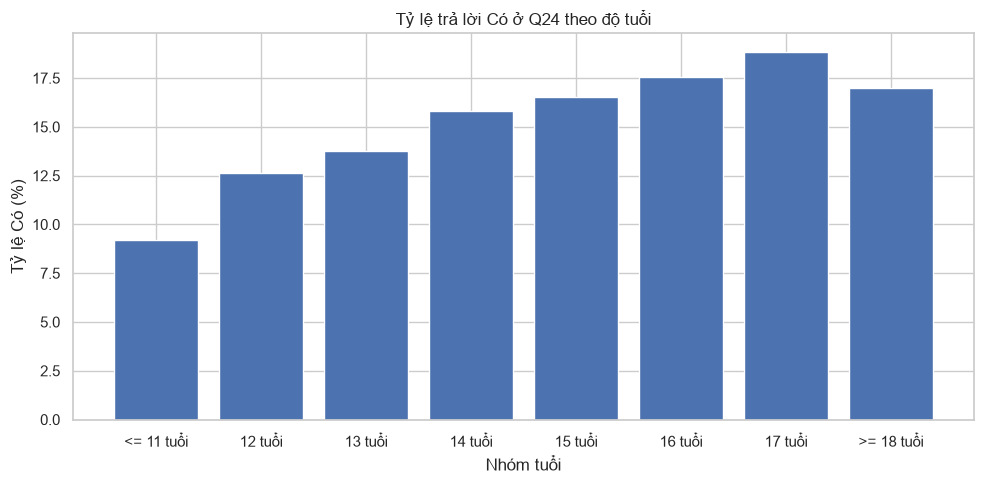

In [35]:
#Nhóm tuổi
age_numeric = pd.to_numeric(df[age_col], errors="coerce")

age_target_df = pd.DataFrame({
    "age": age_numeric,
    "target": target_raw
})

age_target_df = age_target_df[
    age_target_df["age"].isin(age_labels.keys())
    & age_target_df["target"].isin([1, 2])
].copy()

age_target_df["age_label"] = age_target_df["age"].map(age_labels)
age_target_df["target_yes"] = (age_target_df["target"] == 1).astype(int)

age_rate = (
    age_target_df.groupby(["age", "age_label"], observed=True)
    .agg(
        So_nguoi_hop_le=("target_yes", "size"),
        So_tra_loi_co=("target_yes", "sum"),
        Ty_le_co=("target_yes", "mean")
    )
    .reset_index()
)

age_rate["Ty_le_co_%"] = (age_rate["Ty_le_co"] * 100).round(2)
age_rate = age_rate.sort_values("age")

display(
    age_rate[[
        "age_label", "So_nguoi_hop_le",
        "So_tra_loi_co", "Ty_le_co_%"
    ]]
)

plt.figure(figsize=(10, 5))
plt.bar(age_rate["age_label"], age_rate["Ty_le_co_%"])
plt.title("Tỷ lệ trả lời Có ở Q24 theo độ tuổi")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Tỷ lệ Có (%)")
plt.tight_layout()
plt.show()

,sex_label,So_nguoi_hop_le,So_tra_loi_co,Ty_le_co_%
0,Nam,3293,493,14.97
1,Nữ,2995,505,16.86


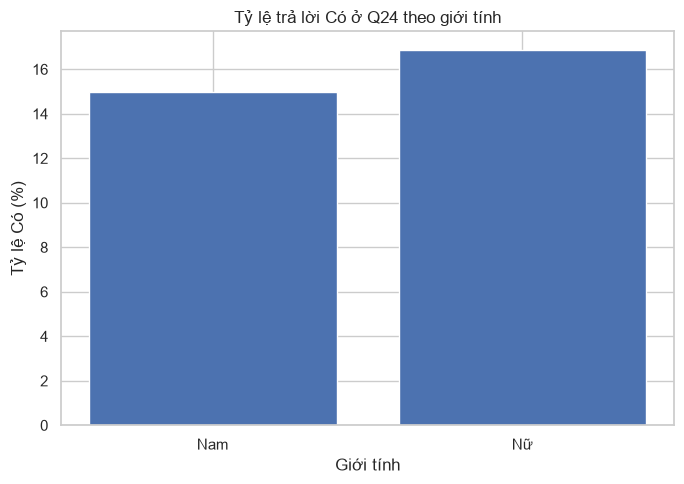

In [36]:
#Giới tính
sex_target_df = pd.DataFrame({
    "sex": sex,
    "target": target_raw
})

sex_target_df = sex_target_df[
    sex_target_df["sex"].isin(sex_labels.keys())
    & sex_target_df["target"].isin([1, 2])
].copy()

sex_target_df["sex_label"] = sex_target_df["sex"].map(sex_labels)
sex_target_df["target_yes"] = (
    sex_target_df["target"] == 1
).astype(int)

sex_rate = (
    sex_target_df.groupby(["sex", "sex_label"], observed=True)
    .agg(
        So_nguoi_hop_le=("target_yes", "size"),
        So_tra_loi_co=("target_yes", "sum"),
        Ty_le_co=("target_yes", "mean")
    )
    .reset_index()
)

sex_rate["Ty_le_co_%"] = (sex_rate["Ty_le_co"] * 100).round(2)

display(
    sex_rate[[
        "sex_label", "So_nguoi_hop_le",
        "So_tra_loi_co", "Ty_le_co_%"
    ]]
)

plt.figure(figsize=(7, 5))
plt.bar(sex_rate["sex_label"], sex_rate["Ty_le_co_%"])
plt.title("Tỷ lệ trả lời Có ở Q24 theo giới tính")
plt.xlabel("Giới tính")
plt.ylabel("Tỷ lệ Có (%)")
plt.tight_layout()
plt.show()

Bảng tỷ lệ theo cả độ tuổi và giới tính

,age,age_label,sex_label,Tong_so_nguoi,So_nguoi_hop_le,So_thieu_Q24,So_tra_loi_co,Ty_le_co_%
0,1.0,<= 11 tuổi,Nam,41,34,7,3,8.82
1,1.0,<= 11 tuổi,Nữ,53,51,2,4,7.84
2,2.0,12 tuổi,Nam,318,304,14,42,13.82
3,2.0,12 tuổi,Nữ,387,377,10,43,11.41
4,3.0,13 tuổi,Nam,508,463,45,68,14.69
5,3.0,13 tuổi,Nữ,521,509,12,65,12.77
6,4.0,14 tuổi,Nam,585,544,41,75,13.79
7,4.0,14 tuổi,Nữ,551,532,19,95,17.86
8,5.0,15 tuổi,Nam,561,531,30,88,16.57
9,5.0,15 tuổi,Nữ,487,468,19,75,16.03


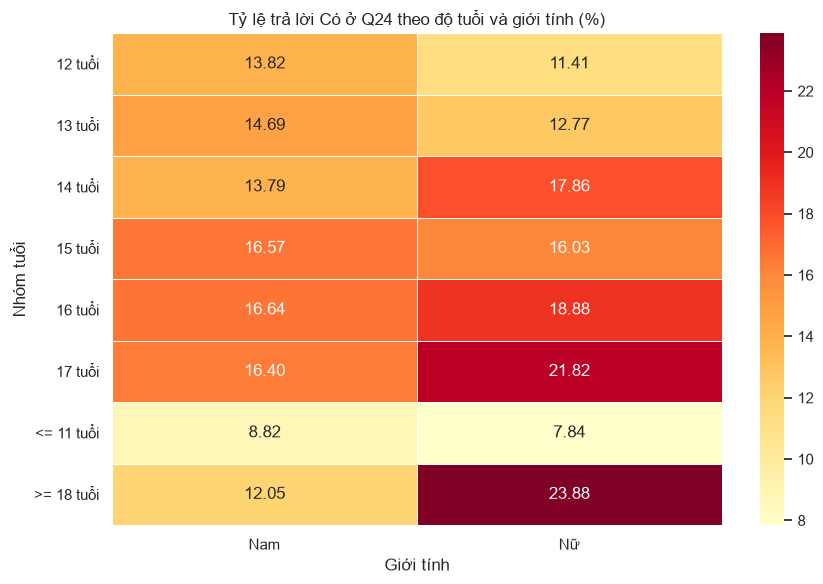

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chuẩn hóa dữ liệu
age_numeric = pd.to_numeric(age_numeric, errors="coerce")
sex = pd.to_numeric(sex, errors="coerce")
target_raw = pd.to_numeric(target_raw, errors="coerce")

# Tạo DataFrame
age_sex_df = pd.DataFrame({
    "age": age_numeric,
    "sex": sex,
    "target": target_raw
})

# Chỉ giữ mã tuổi và giới tính hợp lệ để phân tích theo nhóm
age_sex_df = age_sex_df[
    age_sex_df["age"].isin(age_labels.keys())
    & age_sex_df["sex"].isin(sex_labels.keys())
].copy()

# Tạo nhãn dễ đọc
age_sex_df["age_label"] = age_sex_df["age"].map(age_labels)
age_sex_df["sex_label"] = age_sex_df["sex"].map(sex_labels)

# Xác định Q24 có hợp lệ hay không
age_sex_df["q24_valid"] = age_sex_df["target"].isin([1, 2])

# Xác định câu trả lời Có
age_sex_df["target_yes"] = (
    age_sex_df["target"] == 1
).astype(int)

# Thống kê theo độ tuổi và giới tính
age_sex_rate = (
    age_sex_df.groupby(
        ["age", "age_label", "sex_label"],
        observed=True,
        dropna=False
    )
    .agg(
        Tong_so_nguoi=("target", "size"),
        So_nguoi_hop_le=("q24_valid", "sum"),
        So_thieu_Q24=("q24_valid",
                      lambda x: (~x).sum()),
        So_tra_loi_co=("target_yes",
                       lambda x: x[age_sex_df.loc[x.index, "q24_valid"]].sum())
    )
    .reset_index()
)

# Tính tỷ lệ Có trên số câu trả lời Q24 hợp lệ
age_sex_rate["Ty_le_co_%"] = np.where(
    age_sex_rate["So_nguoi_hop_le"] > 0,
    age_sex_rate["So_tra_loi_co"]
    / age_sex_rate["So_nguoi_hop_le"] * 100,
    np.nan
).round(2)

# Hiển thị bảng kết quả
display(
    age_sex_rate[[
        "age",
        "age_label",
        "sex_label",
        "Tong_so_nguoi",
        "So_nguoi_hop_le",
        "So_thieu_Q24",
        "So_tra_loi_co",
        "Ty_le_co_%"
    ]].sort_values(["age", "sex_label"])
)

# Tạo bảng tỷ lệ để vẽ heatmap
pivot_rates = age_sex_rate.pivot(
    index="age_label",
    columns="sex_label",
    values="Ty_le_co_%"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    pivot_rates,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    mask=pivot_rates.isna()
)

plt.title("Tỷ lệ trả lời Có ở Q24 theo độ tuổi và giới tính (%)")
plt.xlabel("Giới tính")
plt.ylabel("Nhóm tuổi")
plt.tight_layout()
plt.show()

### 2.7. Các yếu tố liên quan đến môi trường và trải nghiệm cá nhân

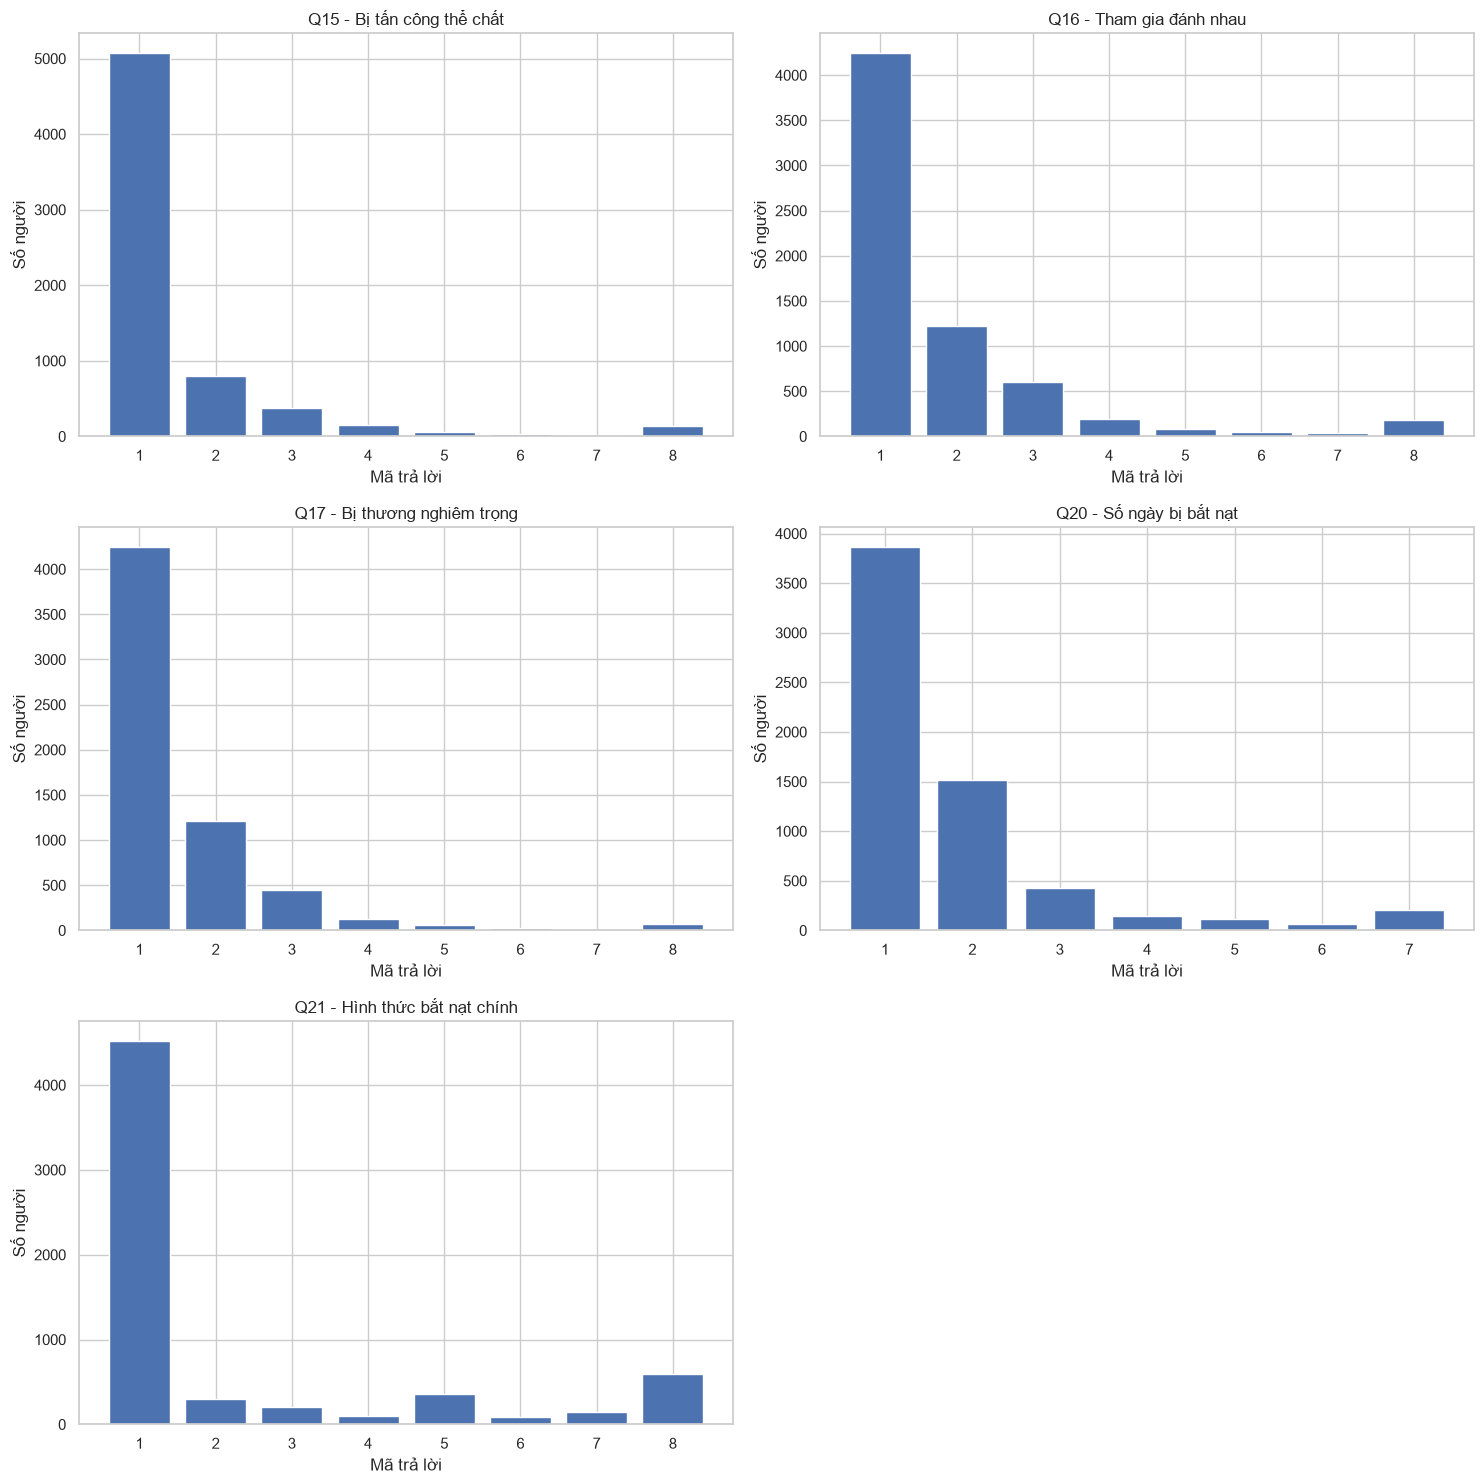

In [39]:
event_questions = [15, 16, 17, 20, 21]

event_titles = {
    15: "Q15 - Bị tấn công thể chất",
    16: "Q16 - Tham gia đánh nhau",
    17: "Q17 - Bị thương nghiêm trọng",
    20: "Q20 - Số ngày bị bắt nạt",
    21: "Q21 - Hình thức bắt nạt chính"
}

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, q in enumerate(event_questions):
    col = find_question_column(df, q)
    values = pd.to_numeric(df[col], errors="coerce")

    # Chỉ vẽ các mã hợp lệ theo dải mã của câu hỏi.
    if q in [15, 16, 17]:
        valid_values = values[values.isin(range(1, 9))]
        categories = list(range(1, 9))
    elif q == 20:
        valid_values = values[values.isin(range(1, 8))]
        categories = list(range(1, 8))
    else:
        valid_values = values[values.isin(range(1, 9))]
        categories = list(range(1, 9))

    counts = valid_values.value_counts().reindex(
        categories, fill_value=0
    )

    axes[i].bar(
        [str(x) for x in categories],
        counts.values
    )
    axes[i].set_title(event_titles[q])
    axes[i].set_xlabel("Mã trả lời")
    axes[i].set_ylabel("Số người")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

---
# PHẦN 3. TIỀN XỬ LÝ DỮ LIỆU CHO MACHINE LEARNING

Chọn biến đầu vào

In [40]:
# 10 biến đầu vào được yêu cầu
input_questions = [1, 2, 15, 16, 17, 20, 21, 22, 23, 27]
target_question = 24

# Tìm tên cột thực tế trong DataFrame
input_columns = [
    find_question_column(df, q)
    for q in input_questions
]

target_column = find_question_column(df, target_question)

print("Các biến đầu vào:")
for q, col in zip(input_questions, input_columns):
    print(f"Q{q}: {col}")

print(f"\nBiến mục tiêu Q24: {target_column}")

# Tạo DataFrame chỉ chứa 10 biến đầu vào và Q24
data = df[input_columns + [target_column]].copy()

print("\nKích thước dữ liệu ban đầu:", data.shape)
display(data.head())

Các biến đầu vào:
Q1: Q1
Q2: Q2
Q15: Q15
Q16: Q16
Q17: Q17
Q20: Q20
Q21: Q21
Q22: Q22
Q23: Q23
Q27: Q27

Biến mục tiêu Q24: Q24

Kích thước dữ liệu ban đầu: (6745, 11)


,Q1,Q2,Q15,Q16,Q17,Q20,Q21,Q22,Q23,Q27,Q24
0,5.0,1.0,7.0,NaN,4.0,4.0,2.0,NaN,2.0,NaN,NaN
1,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0
2,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,2.0
3,4.0,1.0,6.0,6.0,5.0,3.0,2.0,4.0,4.0,1.0,1.0
4,2.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,4.0,2.0


### 3.1. Chuẩn hóa dữ liệu thiếu

In [41]:
# Chuẩn hóa các chuỗi thường dùng để biểu diễn giá trị thiếu
missing_strings = [
    "", " ", "NA", "N/A", "NaN", "nan",
    "NULL", "null", "Sysmiss", "SYSMISS"
]

data = data.replace(missing_strings, np.nan)

# Chuyển các cột được chọn sang dạng số
for col in input_columns + [target_column]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Phân bố mã Q24 trước khi lọc:")
display(data[target_column].value_counts(dropna=False).sort_index())

# Chỉ Q24 = 1 hoặc Q24 = 2 là nhãn hợp lệ
valid_target_mask = data[target_column].isin([1, 2])

print("\nTổng số dòng:", len(data))
print("Số dòng có Q24 hợp lệ:", int(valid_target_mask.sum()))
print("Số dòng Q24 thiếu hoặc không hợp lệ:",
      int((~valid_target_mask).sum()))

Phân bố mã Q24 trước khi lọc:


Q24
1.0    1031
2.0    5396
NaN     318
Name: count, dtype: int64


Tổng số dòng: 6745
Số dòng có Q24 hợp lệ: 6427
Số dòng Q24 thiếu hoặc không hợp lệ: 318


### 3.2. Mã hóa biến mục tiêu

In [42]:
# Chỉ giữ các dòng có nhãn mục tiêu hợp lệ
data_valid = data.loc[valid_target_mask].copy()

# Mã hóa:
# Q24 = 1 -> 1 (Có)
# Q24 = 2 -> 0 (Không)
data_valid["target"] = (
    data_valid[target_column] == 1
).astype("int64")

# Bỏ cột Q24 dạng mã gốc, giữ cột target
X = data_valid[input_columns].copy()
y = data_valid["target"].copy()

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nPhân bố nhãn:")
display(
    y.value_counts()
    .rename(index={0: "Không", 1: "Có"})
    .to_frame("Số người")
)

print("\nTỷ lệ nhãn (%):")
display(
    (y.value_counts(normalize=True) * 100)
    .rename(index={0: "Không", 1: "Có"})
    .round(2)
    .to_frame("Tỷ lệ (%)")
)

Kích thước X: (6427, 10)
Kích thước y: (6427,)

Phân bố nhãn:


,Số người
target,
Không,5396
Có,1031



Tỷ lệ nhãn (%):


,Tỷ lệ (%)
target,
Không,83.96
Có,16.04


### 3.3. Kiểm tra dữ liệu thiếu ở biến đầu vào

,So_luong_thieu,Ty_le_thieu_%
Q1,100,1.56
Q2,139,2.16
Q15,52,0.81
Q16,87,1.35
Q17,497,7.73
Q20,344,5.35
Q21,363,5.65
Q22,114,1.77
Q23,31,0.48
Q27,125,1.94


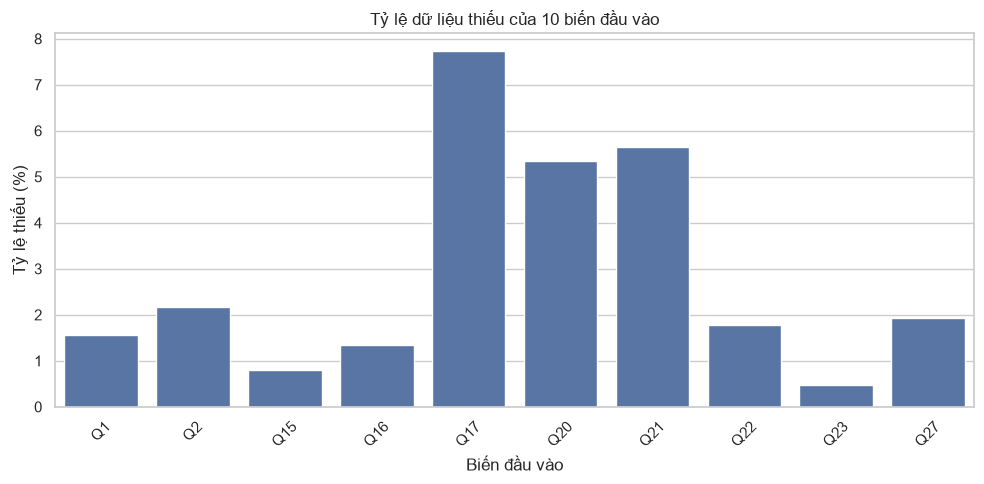

In [43]:
missing_input_summary = pd.DataFrame({
    "So_luong_thieu": X.isna().sum(),
    "Ty_le_thieu_%": (X.isna().mean() * 100).round(2)
})

display(missing_input_summary)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=missing_input_summary.index,
    y=missing_input_summary["Ty_le_thieu_%"]
)
plt.title("Tỷ lệ dữ liệu thiếu của 10 biến đầu vào")
plt.xlabel("Biến đầu vào")
plt.ylabel("Tỷ lệ thiếu (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.4. Chia dữ liệu thành tập huấn luyện (Train) và tập kiểm tra (Test)

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Chia dữ liệu trước khi fit bộ xử lý thiếu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTỷ lệ lớp trong tập huấn luyện:")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTỷ lệ lớp trong tập kiểm tra:")
display((y_test.value_counts(normalize=True) * 100).round(2))

# Pipeline tiền xử lý:
# 1. Điền dữ liệu thiếu bằng trung vị
# 2. Chuẩn hóa thang đo
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fit chỉ trên tập train, sau đó biến đổi train và test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nKích thước X_train sau tiền xử lý:",
      X_train_processed.shape)
print("Kích thước X_test sau tiền xử lý:",
      X_test_processed.shape)

print("\nSố lượng giá trị thiếu sau tiền xử lý:")
print("Train:", np.isnan(X_train_processed).sum())
print("Test :", np.isnan(X_test_processed).sum())

X_train: (5141, 10)
X_test : (1286, 10)
y_train: (5141,)
y_test : (1286,)

Tỷ lệ lớp trong tập huấn luyện:


target
0    83.95
1    16.05
Name: proportion, dtype: float64


Tỷ lệ lớp trong tập kiểm tra:


target
0    83.98
1    16.02
Name: proportion, dtype: float64


Kích thước X_train sau tiền xử lý: (5141, 10)
Kích thước X_test sau tiền xử lý: (1286, 10)

Số lượng giá trị thiếu sau tiền xử lý:
Train: 0
Test : 0


### 3.5. Kết luận

Trong phần tiền xử lý, dữ liệu được giới hạn vào 10 biến đầu vào đã xác định và biến mục tiêu Q24. Những dòng không có nhãn Q24 hợp lệ được loại khỏi tập học có giám sát; các nhãn Có/Không được chuyển thành 1/0.

Dữ liệu được chia thành tập huấn luyện và tập kiểm tra theo tỷ lệ 80:20. Bộ điền giá trị thiếu và chuẩn hóa được fit trên tập huấn luyện rồi áp dụng lên tập kiểm tra.

Trước khi sang bước xây dựng mô hình, cần kiểm tra số lượng mẫu còn lại, tỷ lệ lớp Có/Không và tỷ lệ thiếu của từng biến. Do Q24 có nhiều trường hợp thiếu theo codebook, kết quả mô hình chỉ phản ánh những người có câu trả lời Q24 hợp lệ và có thể chịu ảnh hưởng của sai lệch do thiếu dữ liệu.

---
# PHẦN 4. XÂY DỰNG VÀ ĐÁNH GIÁ CÁC MÔ HÌNH MACHINE LEARNING

## Chỉ số đánh giá mô hình 


- TN (True Negative) - Dự đoán âm tính đúng (dự đoán Không và thực tế cũng là Không)
- FP (False Positive)- Dự đoán dương tính sai (dự đoán Có và thực tế là Không)
- FN (False Negative)- Dự đoán âm tính sai (dự đoán Không và thực tế là Có)
- TP (True Positive) - Dự đoán dương tính đúng (dự đoán Có và thực tế cũng là Có)

- Accuracy - Độ chính xác tổng thể = $\frac{TP + TN}{TP + TN + FP + FN}$
- Precision - Độ chính xác của dự đoán Có = $\frac{TP}{TP + FP}$
- Recall - Khả năng nhận diện nhóm Có = $\frac{TP}{TP + FN}$
- F1-score - Chỉ số đánh giá mô hình Machine Learning = 2 x $\frac{Precision * Recall}{Precision + Recall}$
- ROC-AUC - Chỉ số đo lường khả năng phân biệt hai lớp của mô hình phân loại :


    - ROC-AUC là diện tích đường cong ROC(Receiver Operating Characteristic)

    - Đường ROC biểu diễn mối quan hệ giữa: 

        + TPR (True Positive Rate)- chính là Recall = $\frac{TP}{TP + FN}$


        + FPR(False Positive Rate)- tỷ lệ dự đoán nhầm nhóm Không thành Có = $\frac{FP}{FP + TN}$

    - ROC-AUC được tính bằng tích phân: $$AUC_{ROC} = \int_0^1 TPR(FPR) \, d(FPR)$$
- RP-AUC - Chỉ số đánh giá hiệu quả của mô hình phân loại:


    - PR-AUC(Precision-Recall Area Under the Curve) là diện tích dưới đường cong Precision-Recall
    $$AUC_{PR} = \int_0^1 Precision(Recall) \, d(Recall)$$



## 4.2. Mô hình Logistic Regression

### 4.2.1. Giới thiệu mô hình Logistic Regression

Logistic Regression là thuật toán học có giám sát thường được sử dụng cho bài toán phân loại nhị phân. Mô hình ước lượng xác suất một mẫu thuộc một lớp dựa trên các đặc trưng đầu vào.

Trong đề tài này, Logistic Regression được sử dụng để dự đoán câu trả lời Q24: người tham gia khảo sát có nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua hay không.

Biến mục tiêu được mã hóa như sau:
- 1: Có.
- 0: Không.
Các đặc trưng đầu vào gồm 10 biến: Q1, Q2, Q15, Q16, Q17, Q20, Q21, Q22, Q23 và Q27.

Logistic Regression có ưu điểm là tương đối dễ diễn giải, thời gian huấn luyện nhanh và có thể cung cấp xác suất dự đoán. Tuy nhiên, mô hình có thể không biểu diễn tốt những mối quan hệ phi tuyến phức tạp nếu không có bước xây dựng đặc trưng phù hợp.

### 4.2.2. Xây dựng quy trình tiền xử lý bằng SimpleImputer và StandardScaler

Logistic Regression thường hoạt động tốt hơn khi các đặc trưng số được chuẩn hóa. Ngoài ra, mô hình không thể trực tiếp xử lý giá trị thiếu nên cần sử dụng SimpleImputer.

Quy trình tiền xử lý gồm:
1. Dùng SimpleImputer(strategy="median") để thay thế giá trị thiếu bằng trung vị của từng đặc trưng.
2. Dùng StandardScaler() để chuẩn hóa đặc trưng.
3. Chỉ fit bộ tiền xử lý trên tập Train, sau đó dùng cùng bộ đó để biến đổi tập Test nhằm tránh rò rỉ dữ liệu.

In [45]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_lr = lr_preprocessor.fit_transform(X_train)
X_test_lr = lr_preprocessor.transform(X_test)

print("Kích thước X_train sau tiền xử lý:", X_train_lr.shape)
print("Kích thước X_test sau tiền xử lý:", X_test_lr.shape)

Kích thước X_train sau tiền xử lý: (5141, 10)
Kích thước X_test sau tiền xử lý: (1286, 10)


### 4.2.3. Khởi tạo và cấu hình mô hình

In [46]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="lbfgs",
    random_state=42
)

print(logistic_model)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)


Ý nghĩa các tham số:
- max_iter=2000: cho phép thuật toán thực hiện nhiều vòng lặp để tìm nghiệm.
- class_weight="balanced": điều chỉnh trọng số lớp theo tần suất xuất hiện của chúng trong tập Train.
- solver="lbfgs": thuật toán tối ưu hóa được sử dụng để ước lượng hệ số.
- random_state=42: cố định yếu tố ngẫu nhiên nếu có, hỗ trợ tái lập kết quả.

### 4.2.4. Huấn luyện mô hình trên tập Train

In [47]:
logistic_model.fit(X_train_lr, y_train)

print("Huấn luyện Logistic Regression hoàn tất.")
print("Số đặc trưng đầu vào:", logistic_model.n_features_in_)
print("Hệ số mô hình:", logistic_model.coef_)
print("Hệ số chệch:", logistic_model.intercept_)

Huấn luyện Logistic Regression hoàn tất.
Số đặc trưng đầu vào: 10
Hệ số mô hình: [[ 2.14608820e-02  1.67058864e-04  2.06375826e-01  1.60504633e-01
   1.29254997e-01  1.74632112e-01  2.32189851e-02  2.05110065e-01
   2.62665000e-01 -2.79088994e-01]]
Hệ số chệch: [-0.18749995]


### 4.2.5. Dự đoán trên tập Test

In [48]:
y_pred_lr = logistic_model.predict(X_test_lr)

# Xác suất thuộc lớp Có (nhãn 1)
y_prob_lr = logistic_model.predict_proba(X_test_lr)[:, 1]

print("10 nhãn thực tế đầu tiên:")
print(y_test.iloc[:10].to_list())

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred_lr[:10])

print("\n10 xác suất dự đoán thuộc lớp Có:")
print(y_prob_lr[:10].round(4))

10 nhãn thực tế đầu tiên:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

10 nhãn dự đoán đầu tiên:
[0 0 0 1 0 0 1 0 1 0]

10 xác suất dự đoán thuộc lớp Có:
[0.3225 0.2859 0.3404 0.506  0.4641 0.3506 0.5446 0.2249 0.784  0.333 ]


### 4.2.6. Đánh giá mô hình: Accuracy, Precision, Recall, F1-score

In [49]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metrics_lr = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
}

results_lr = pd.DataFrame(
    list(metrics_lr.items()),
    columns=["Chỉ số", "Giá trị"]
)

display(results_lr.round(4))

,Chỉ số,Giá trị
0,Accuracy,0.7068
1,Precision,0.2988
2,Recall,0.6165
3,F1-score,0.4025
4,ROC-AUC,0.7281


### 4.2.7. Phân tích Confusion Matrix

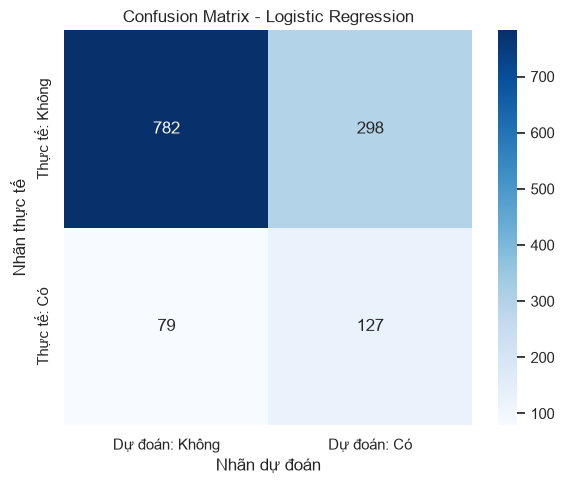

              precision    recall  f1-score   support

       Không       0.91      0.72      0.81      1080
          Có       0.30      0.62      0.40       206

    accuracy                           0.71      1286
   macro avg       0.60      0.67      0.60      1286
weighted avg       0.81      0.71      0.74      1286



In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dự đoán: Không", "Dự đoán: Có"],
    yticklabels=["Thực tế: Không", "Thực tế: Có"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    target_names=["Không", "Có"],
    zero_division=0
))

### 4.2.8. Điều chỉnh ngưỡng dự đoán (Decision Threshold)
Ngưỡng mặc định thường là 0.5. Nếu xác suất dự đoán thuộc lớp Có lớn hơn hoặc bằng ngưỡng, mô hình phân loại mẫu thành Có.

Giảm ngưỡng có thể làm tăng Recall nhưng thường khiến Precision giảm. Tăng ngưỡng có thể cải thiện Precision trong một số trường hợp nhưng làm tăng số trường hợp Có bị bỏ sót.

In [51]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "FN": confusion_matrix(
            y_test, y_pred_threshold, labels=[0, 1]
        )[1, 0],
        "FP": confusion_matrix(
            y_test, y_pred_threshold, labels=[0, 1]
        )[0, 1]
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,FN,FP
0,0.3,0.1902,0.9223,0.3154,16,809
1,0.4,0.2334,0.7670,0.3579,48,519
2,0.5,0.2988,0.6165,0.4025,79,298
3,0.6,0.3755,0.4320,0.4018,117,148
4,0.7,0.4609,0.2864,0.3533,147,69


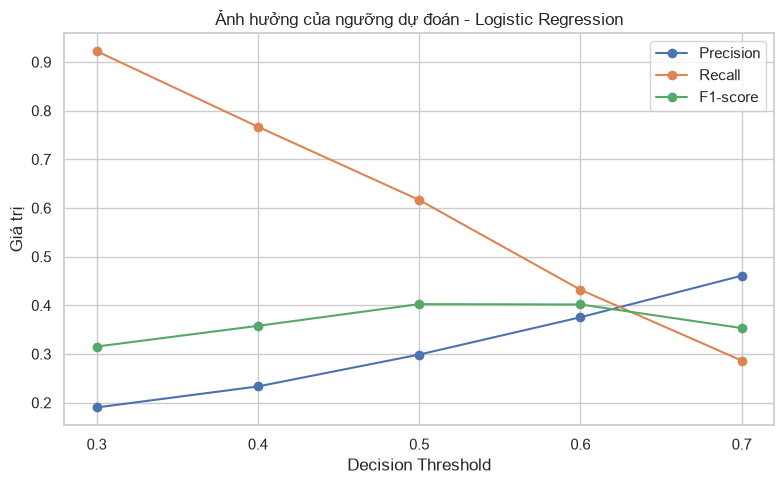

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Giá trị")
plt.title("Ảnh hưởng của ngưỡng dự đoán - Logistic Regression")
plt.xticks(thresholds)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### 4.2.9. Nhận xét và kết luận

- **Hiệu quả phân loại:** Logistic Regression đạt Accuracy = 0.7068, Precision = 0.2988, Recall = 0.6165, F1-score = 0.4025 và ROC-AUC = 0.7281 trên tập Test. Kết quả cho thấy mô hình có khả năng phân biệt hai lớp ở mức tương đối, tuy nhiên hiệu quả dự đoán lớp “Có” vẫn còn hạn chế.

- **Khả năng phát hiện lớp “Có”:** Tại ngưỡng 0.5, Recall đạt 0.6165. Confusion Matrix cho thấy mô hình phát hiện đúng 127 trường hợp “Có” và bỏ sót 79 trường hợp thực tế thuộc lớp “Có”. Ngoài ra, mô hình dự đoán nhầm 298 trường hợp thực tế thuộc lớp “Không” thành “Có”. Điều này cho thấy mô hình phát hiện được khoảng 61,65% trường hợp thực tế thuộc lớp “Có”, nhưng vẫn còn nhiều dự đoán dương tính giả.

- **Ảnh hưởng của ngưỡng:** 
    - Khi tăng ngưỡng dự đoán từ 0.3 lên 0.7, Precision tăng từ 0.1902 lên 0.4609.
    - Trong khi Recall giảm từ 0.9223 xuống 0.2864. 
    - F1-score tăng từ 0.3154 tại ngưỡng 0.3 lên mức cao nhất 0.4025 tại ngưỡng 0.5, sau đó giảm xuống 0.4018 tại ngưỡng 0.6 và 0.3533 tại ngưỡng 0.7. 
    - Điều này cho thấy khi ngưỡng dự đoán tăng, độ chính xác của các dự đoán lớp “Có” được cải thiện, nhưng khả năng phát hiện đầy đủ các trường hợp thực tế thuộc lớp này giảm. 
    - Trong các ngưỡng được so sánh, ngưỡng 0.5 cho F1-score cao nhất, thể hiện sự cân bằng tốt nhất giữa Precision và Recall theo chỉ số này.

- **Ưu điểm:** Mô hình tương đối dễ giải thích, có thời gian huấn luyện nhanh và hỗ trợ dự đoán xác suất. Việc điều chỉnh ngưỡng phân loại giúp linh hoạt lựa chọn giữa khả năng phát hiện lớp “Có” và khả năng hạn chế các trường hợp dự đoán dương tính giả.

- **Hạn chế:** Precision tại ngưỡng 0.5 chỉ đạt 0.2988, cho thấy trong các trường hợp được dự đoán là “Có”, tỷ lệ dự đoán đúng còn thấp. ROC-AUC = 0.7281 cho thấy khả năng phân biệt hai lớp của mô hình vẫn còn hạn chế. Bên cạnh đó, mô hình có thể không nắm bắt tốt các mối quan hệ phi tuyến phức tạp; chất lượng dự đoán phụ thuộc vào cách mã hóa biến, xử lý dữ liệu thiếu và đặc điểm phân bố của dữ liệu khảo sát. Việc tăng ngưỡng có thể cải thiện Precision nhưng đồng thời làm giảm Recall, dẫn đến nguy cơ bỏ sót nhiều trường hợp thực tế thuộc lớp “Có” hơn.

## 4.3. Mô hình Decision Tree

### 4.3.1. Giới thiệu mô hình Decision Tree

Decision Tree (cây quyết định) là thuật toán học có giám sát được sử dụng cho bài toán phân loại và hồi quy. Thuật toán xây dựng một cây gồm các nút quyết định, các nhánh và các nút lá. Mỗi nút quyết định kiểm tra một điều kiện trên đặc trưng đầu vào, sau đó phân chia dữ liệu thành các nhóm nhỏ hơn.

Trong đề tài này, Decision Tree được sử dụng để dự đoán biến mục tiêu Q24, phản ánh việc người tham gia khảo sát có nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua hay không. Biến mục tiêu được mã hóa như sau:
- 1: Có.
- 0: Không.
Các biến đầu vào gồm 10 đặc trưng đã lựa chọn trong phần tiền xử lý. Mô hình có ưu điểm là dễ giải thích, có thể trực quan hóa cấu trúc cây và không yêu cầu chuẩn hóa dữ liệu về mặt nguyên lý.

### 4.3.2. Nguyên lý hoạt động và tiêu chí phân chia nút

Decision Tree lựa chọn đặc trưng và ngưỡng phân chia sao cho các nhóm dữ liệu sau khi chia trở nên đồng nhất hơn về nhãn mục tiêu.

Một tiêu chí phổ biến là Gini Impurity, được tính theo công thức:
$
Gini(D)=1-\sum_{k=1}^{K}p_k^2
$

Trong đó:
- D là tập dữ liệu tại một nút.
- K là số lớp.
- $p_k$ là tỷ lệ mẫu thuộc lớp $k$.
Gini càng nhỏ thì các mẫu tại nút càng tập trung vào một lớp. Với bài toán nhị phân, Gini bằng 0 khi tất cả mẫu tại nút thuộc cùng một lớp.

Ngoài Gini, Decision Tree còn có thể sử dụng Entropy và Information Gain. Trong phần thực nghiệm này, ta chọn criterion="gini".

### 4.3.3. Khởi tạo và cấu hình mô hình

In [53]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

print(decision_tree)

DecisionTreeClassifier(class_weight='balanced', max_depth=6,
                       min_samples_leaf=10, min_samples_split=20,
                       random_state=42)


Ý nghĩa các tham số:
- criterion="gini": sử dụng Gini Impurity để lựa chọn cách chia nút.
- max_depth=6: giới hạn độ sâu cây để hạn chế cây quá phức tạp.
- min_samples_split=20: một nút phải có ít nhất 20 mẫu mới được xét chia tiếp.
- min_samples_leaf=10: mỗi nút lá phải có tối thiểu 10 mẫu.
- class_weight="balanced": tự điều chỉnh trọng số theo tần suất các lớp.
- random_state=42: cố định yếu tố ngẫu nhiên để dễ tái lập kết quả.

### 4.3.4. Huấn luyện mô hình trên tập Train

In [54]:
decision_tree.fit(X_train_processed, y_train)

print("Huấn luyện Decision Tree hoàn tất.")
print("Độ sâu thực tế của cây:", decision_tree.get_depth())
print("Số nút trong cây:", decision_tree.tree_.node_count)

Huấn luyện Decision Tree hoàn tất.
Độ sâu thực tế của cây: 6
Số nút trong cây: 97


### 4.3.5. Dự đoán trên tập Test

In [55]:
y_pred_dt = decision_tree.predict(X_test_processed)

print("10 nhãn thực tế đầu tiên:")
print(y_test.iloc[:10].to_list())

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred_dt[:10])

10 nhãn thực tế đầu tiên:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

10 nhãn dự đoán đầu tiên:
[0 0 0 1 0 0 0 0 1 0]


Mô hình dự đoán 1 khi phân loại mẫu vào nhóm Có và 0 khi phân loại vào nhóm Không. Tập Test được giữ riêng trong quá trình huấn luyện để đánh giá khả năng tổng quát hóa của mô hình

### 4.3.6. Đánh giá mô hình: Accuracy, Precision, Recall, F1-score

In [56]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob_dt = decision_tree.predict_proba(X_test_processed)[:, 1]

metrics_dt = {
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dt, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_dt, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_dt)
}

results_dt = pd.DataFrame(
    metrics_dt.items(),
    columns=["Chỉ số", "Giá trị"]
)

display(results_dt.round(4))

,Chỉ số,Giá trị
0,Accuracy,0.7162
1,Precision,0.2869
2,Recall,0.5194
3,F1-score,0.3696
4,ROC-AUC,0.6790


### 4.3.7. Phân tích Confusion Matrix

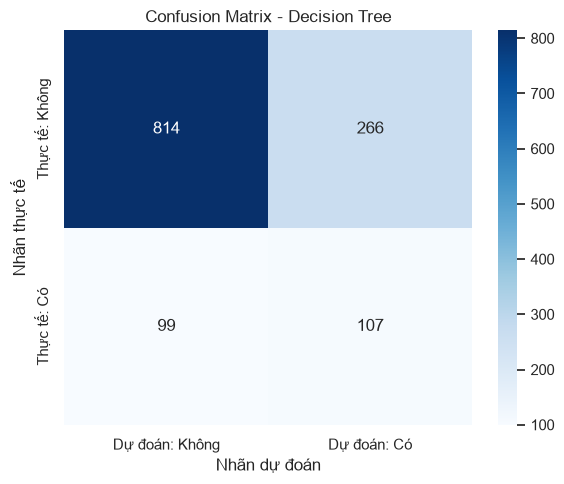

              precision    recall  f1-score   support

       Không       0.89      0.75      0.82      1080
          Có       0.29      0.52      0.37       206

    accuracy                           0.72      1286
   macro avg       0.59      0.64      0.59      1286
weighted avg       0.79      0.72      0.75      1286



In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dự đoán: Không", "Dự đoán: Có"],
    yticklabels=["Thực tế: Không", "Thực tế: Có"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["Không", "Có"],
    zero_division=0
))

### 4.3.8. Phân tích cây quyết định và nguy cơ Overfitting

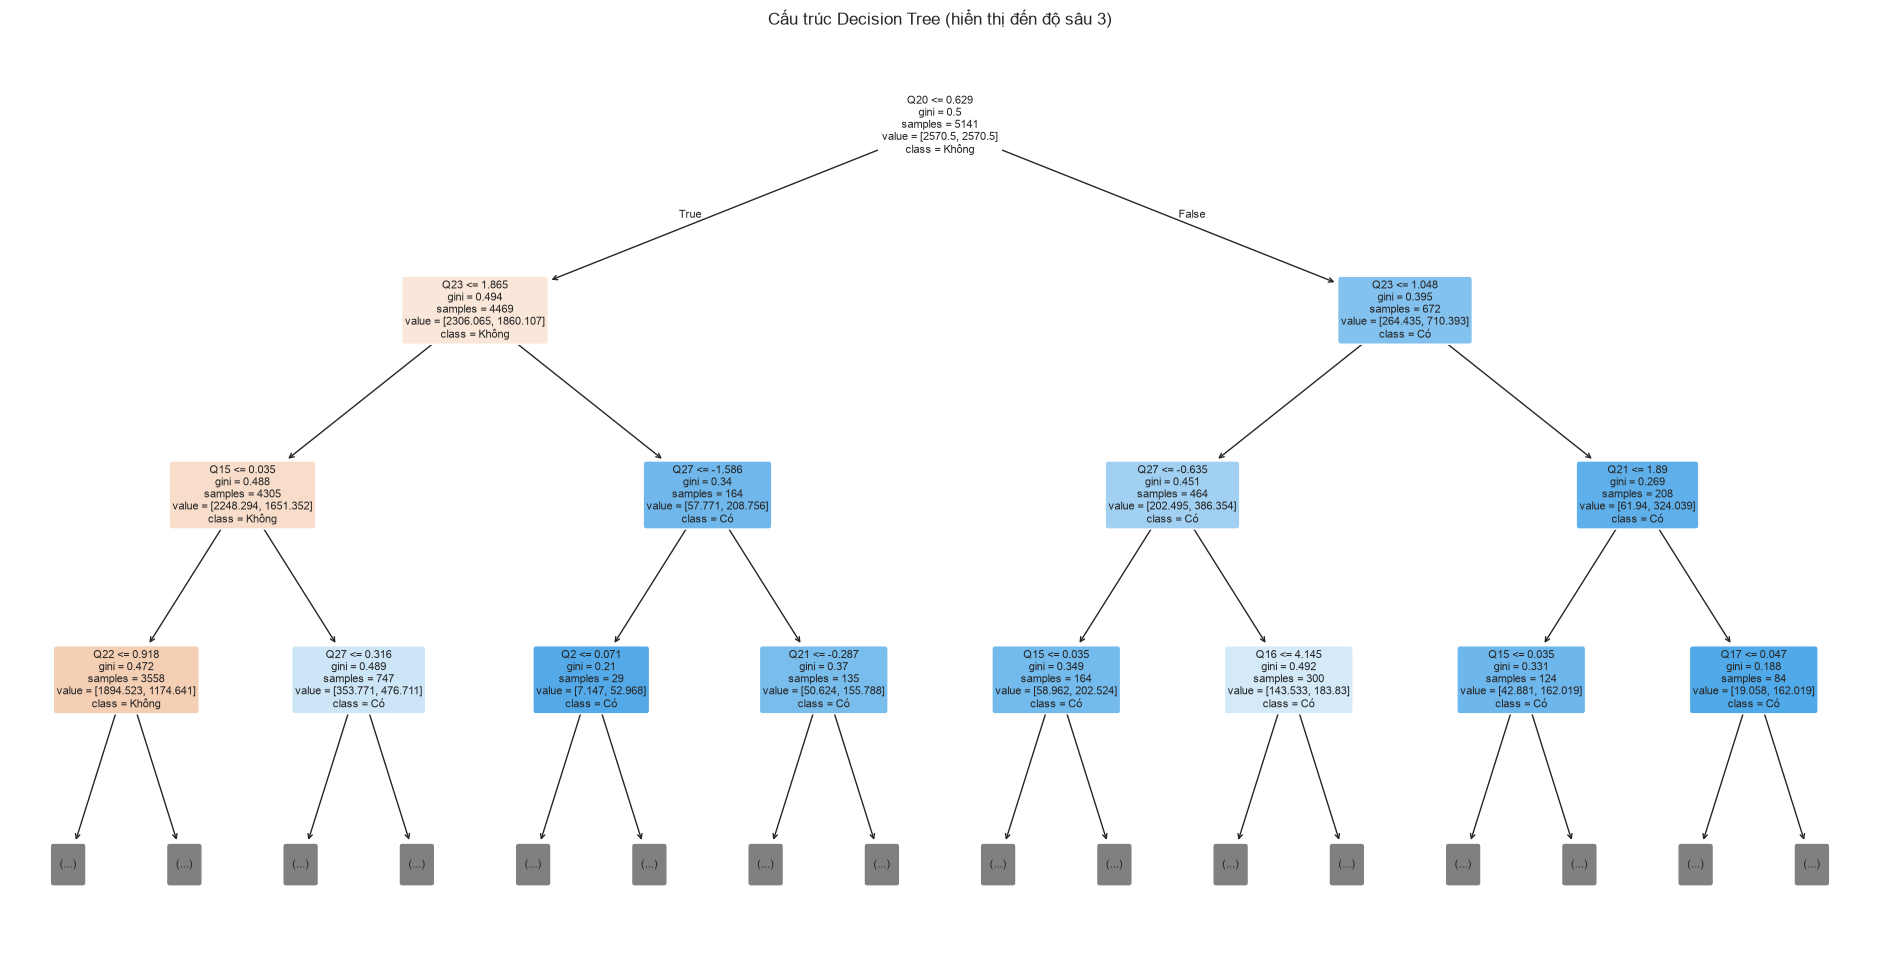

In [58]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree,
    feature_names=input_columns,
    class_names=["Không", "Có"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Cấu trúc Decision Tree (hiển thị đến độ sâu 3)")
plt.show()

In [59]:
from sklearn.metrics import f1_score

y_train_pred_dt = decision_tree.predict(X_train_processed)

f1_train_dt = f1_score(
    y_train, y_train_pred_dt, zero_division=0
)

f1_test_dt = f1_score(
    y_test, y_pred_dt, zero_division=0
)

print(f"F1-score Train: {f1_train_dt:.4f}")
print(f"F1-score Test : {f1_test_dt:.4f}")
print(f"Chênh lệch    : {f1_train_dt - f1_test_dt:.4f}")

F1-score Train: 0.4190
F1-score Test : 0.3696
Chênh lệch    : 0.0494


### 4.3.9. Nhận xét và kết luận

Sau khi chạy notebook, điền nhận xét dựa trên số liệu thực tế:
- Mô hình Decision Tree đạt Accuracy là ..., Precision là ..., Recall là ... và F1-score là ....
- Confusion Matrix cho thấy mô hình phát hiện được ... trường hợp thuộc lớp Có và bỏ sót ... trường hợp.
- F1-score trên Train là ..., trong khi trên Test là .... Chênh lệch này cho thấy mức độ tổng quát hóa của mô hình.
- Việc giới hạn độ sâu và số mẫu tối thiểu tại nút giúp kiểm soát độ phức tạp của cây.
Kết luận cuối cùng cần dựa trên kết quả chạy thật, không nên khẳng định Decision Tree là mô hình tốt nhất trước khi so sánh với Random Forest và Gradient Boosting.

## 4.4. Mô hình Random Forest

### 4.4.1. Giới thiệu mô hình Random Forest

Random Forest là thuật toán học có giám sát kết hợp nhiều cây quyết định thành một mô hình tập hợp (ensemble model). Thay vì chỉ sử dụng một cây, thuật toán xây dựng nhiều cây trên những mẫu dữ liệu và tập đặc trưng ngẫu nhiên khác nhau.

Đối với bài toán Q24, các cây đưa ra dự đoán và Random Forest tổng hợp kết quả để phân loại mẫu vào nhóm Có hoặc Không.

Ưu điểm của mô hình là thường ổn định hơn một cây quyết định đơn lẻ và có thể cung cấp thông tin về mức độ quan trọng của các đặc trưng. Nhược điểm là khó diễn giải toàn bộ mô hình hơn một cây đơn và tốn tài nguyên tính toán hơn.

### 4.4.2. Nguyên lý kết hợp nhiều cây quyết định

Random Forest sử dụng hai ý tưởng chính:
1. Bootstrap sampling: mỗi cây được huấn luyện trên một mẫu lấy ngẫu nhiên có hoàn lại từ tập Train.
2. Random feature selection: tại mỗi lần phân chia, cây chỉ xem xét một tập con các đặc trưng thay vì toàn bộ đặc trưng.
Với bài toán phân loại, mỗi cây tạo ra dự đoán cho mẫu đầu vào. Các dự đoán được tổng hợp thành xác suất hoặc nhãn cuối cùng. Việc kết hợp nhiều cây giúp giảm sự phụ thuộc vào một cây cụ thể.

### 4.4.3. Khởi tạo và cấu hình mô hình

In [60]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print(random_forest)

RandomForestClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=300, n_jobs=-1, random_state=42)


Ý nghĩa các tham số:
- n_estimators=300: xây dựng 300 cây.
- max_depth=12: giới hạn độ sâu của từng cây.
- min_samples_split=10: số mẫu tối thiểu để một nút được xét chia.
- min_samples_leaf=5: số mẫu tối thiểu tại một nút lá.
- class_weight="balanced": điều chỉnh trọng số theo tần suất lớp.
- random_state=42: cố định yếu tố ngẫu nhiên.
- n_jobs=-1: sử dụng tất cả lõi CPU khả dụng mà thư viện có thể dùng.

### 4.4.4. Huấn luyện mô hình trên tập Train

In [61]:
random_forest.fit(X_train_processed, y_train)

print("Huấn luyện Random Forest hoàn tất.")
print("Số cây:", len(random_forest.estimators_))

Huấn luyện Random Forest hoàn tất.
Số cây: 300


### 4.4.5. Dự đoán trên tập Test

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred_rf = random_forest.predict(X_test_processed)
y_prob_rf = random_forest.predict_proba(X_test_processed)[:, 1]

print("10 nhãn thực tế đầu tiên:")
print(y_test.iloc[:10].to_list())

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred_rf[:10])

10 nhãn thực tế đầu tiên:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

10 nhãn dự đoán đầu tiên:
[0 0 0 1 0 0 0 0 1 0]


### 4.4.6. Đánh giá mô hình: Accuracy, Precision, Recall, F1-score

In [63]:
metrics_rf = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
    "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_rf, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

results_rf = pd.DataFrame(
    metrics_rf.items(),
    columns=["Chỉ số", "Giá trị"]
)

display(results_rf.round(4))

,Chỉ số,Giá trị
0,Accuracy,0.7636
1,Precision,0.3478
2,Recall,0.5437
3,F1-score,0.4242
4,ROC-AUC,0.7320


### 4.4.7. Phân tích Confusion Matrix

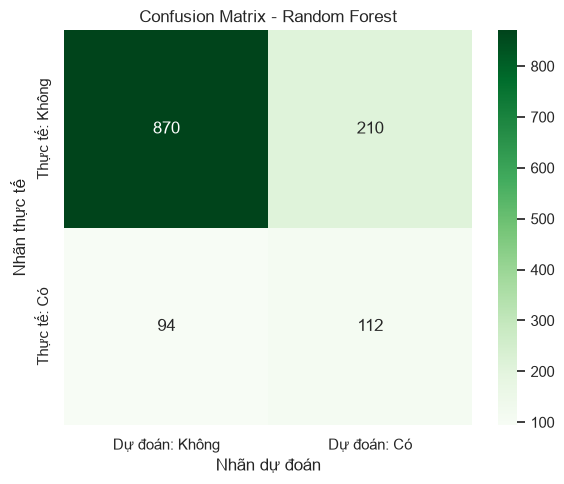

              precision    recall  f1-score   support

       Không       0.90      0.81      0.85      1080
          Có       0.35      0.54      0.42       206

    accuracy                           0.76      1286
   macro avg       0.63      0.67      0.64      1286
weighted avg       0.81      0.76      0.78      1286



In [64]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Dự đoán: Không", "Dự đoán: Có"],
    yticklabels=["Thực tế: Không", "Thực tế: Có"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["Không", "Có"],
    zero_division=0
))

### 4.4.8. Phân tích Feature Importance

,Feature,Importance
8,Q23,0.1563
7,Q22,0.1415
5,Q20,0.1167
0,Q1,0.1160
2,Q15,0.1075
9,Q27,0.1050
3,Q16,0.0795
6,Q21,0.0758
4,Q17,0.0641
1,Q2,0.0376


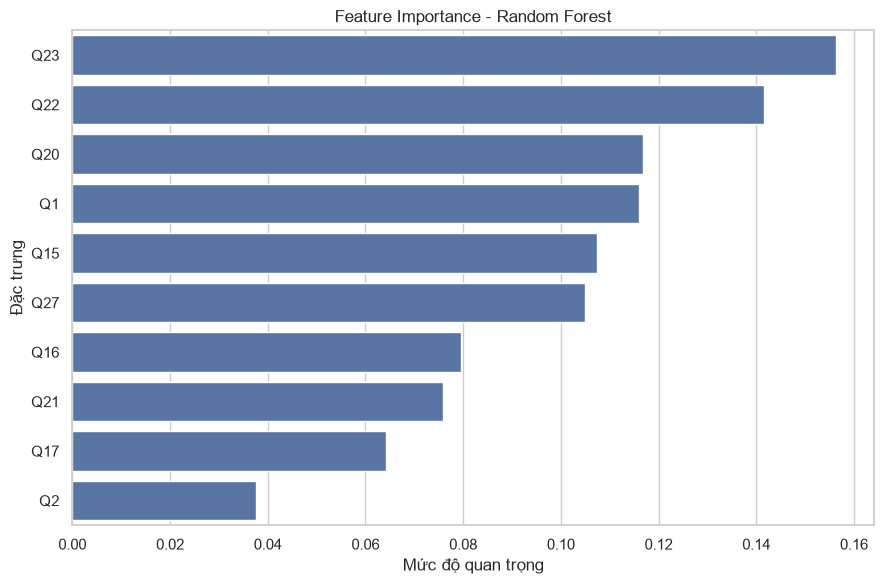

In [65]:
feature_importance_rf = pd.DataFrame({
    "Feature": input_columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance_rf.round(4))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance_rf,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Mức độ quan trọng")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

### 4.4.9. Nhận xét và kết luận

Sau khi chạy các ô code, hoàn thiện nhận xét theo số liệu thực tế:
- Random Forest đạt Accuracy ..., Precision ..., Recall ... và F1-score ....
- Confusion Matrix cho thấy mô hình dự đoán đúng ... trường hợp Có và bỏ sót ... trường hợp Có.
- Các đặc trưng có mức quan trọng cao nhất là ..., ... và ... theo kết quả mô hình.
- So với Decision Tree, cần xem xét liệu Random Forest có cải thiện khả năng tổng quát hóa và phát hiện lớp Có hay không.

## 4.5. Mô hình Gradient Boosting

### 4.5.1. Giới thiệu mô hình Gradient Boosting

Gradient Boosting là thuật toán học tập hợp xây dựng các mô hình yếu theo tuần tự để cải thiện dự đoán. Với bài toán phân loại, các cây sau được xây dựng nhằm giảm sai số của tổ hợp mô hình hiện tại.

Trong đề tài này, Gradient Boosting được dùng để dự đoán nhãn Q24 dựa trên 10 biến đầu vào đã chọn. Mô hình có khả năng học các quan hệ phi tuyến và tương tác giữa đặc trưng, nhưng cần cấu hình cẩn thận để tránh Overfitting.

### 4.5.2. Nguyên lý xây dựng các cây theo tuần tự

Khác với Random Forest, nơi các cây thường được xây dựng độc lập và kết hợp kết quả, Gradient Boosting xây dựng cây theo từng bước:
1. Khởi tạo một dự đoán ban đầu.
2. Đánh giá phần sai số mà mô hình hiện tại chưa giải thích tốt.
3. Huấn luyện cây tiếp theo để điều chỉnh dự đoán hiện tại theo hướng giảm hàm mất mát.
4. Kết hợp cây mới với mô hình trước đó thông qua hệ số học (learning rate).
5. Lặp lại quá trình cho đến khi đạt số cây quy định.
Một số tham số quan trọng gồm n_estimators, learning_rate, max_depth và min_samples_leaf. Learning rate nhỏ thường cần nhiều cây hơn nhưng có thể giúp quá trình học diễn ra thận trọng hơn.

### 4.5.3. Khởi tạo và cấu hình mô hình

In [66]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=10,
    subsample=0.8,
    random_state=42
)

print(gradient_boosting)

GradientBoostingClassifier(learning_rate=0.05, max_depth=2, min_samples_leaf=10,
                           n_estimators=150, random_state=42, subsample=0.8)


Ý nghĩa các tham số:
- n_estimators=150: số cây được xây dựng theo tuần tự.
- learning_rate=0.05: mức đóng góp của từng cây vào mô hình tổng thể.
- max_depth=2: giới hạn độ sâu cây cơ sở để kiểm soát độ phức tạp.
- min_samples_leaf=10: yêu cầu tối thiểu 10 mẫu tại mỗi nút lá.
- subsample=0.8: mỗi bước sử dụng 80% mẫu Train để huấn luyện cây, giúp tăng tính ngẫu nhiên và có thể hạn chế Overfitting.
- random_state=42: cố định yếu tố ngẫu nhiên.

### 4.5.4. Huấn luyện mô hình trên tập Train

In [67]:
gradient_boosting.fit(X_train_processed, y_train)

print("Huấn luyện Gradient Boosting hoàn tất.")
print("Số cây đã xây dựng:", len(gradient_boosting.estimators_))

Huấn luyện Gradient Boosting hoàn tất.
Số cây đã xây dựng: 150


### 4.5.5. Dự đoán trên tập Test

In [68]:
y_pred_gb = gradient_boosting.predict(X_test_processed)
y_prob_gb = gradient_boosting.predict_proba(X_test_processed)[:, 1]

print("10 nhãn thực tế đầu tiên:")
print(y_test.iloc[:10].to_list())

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred_gb[:10])

10 nhãn thực tế đầu tiên:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

10 nhãn dự đoán đầu tiên:
[0 0 0 0 0 0 0 0 0 0]


### 4.5.6. Đánh giá mô hình: Accuracy, Precision, Recall, F1-score

In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metrics_gb = {
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb, zero_division=0),
    "Recall": recall_score(y_test, y_pred_gb, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_gb, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_gb)
}

results_gb = pd.DataFrame(
    metrics_gb.items(),
    columns=["Chỉ số", "Giá trị"]
)

display(results_gb.round(4))

,Chỉ số,Giá trị
0,Accuracy,0.8406
1,Precision,0.5091
2,Recall,0.1359
3,F1-score,0.2146
4,ROC-AUC,0.7292


### 4.5.7. Phân tích Confusion Matrix

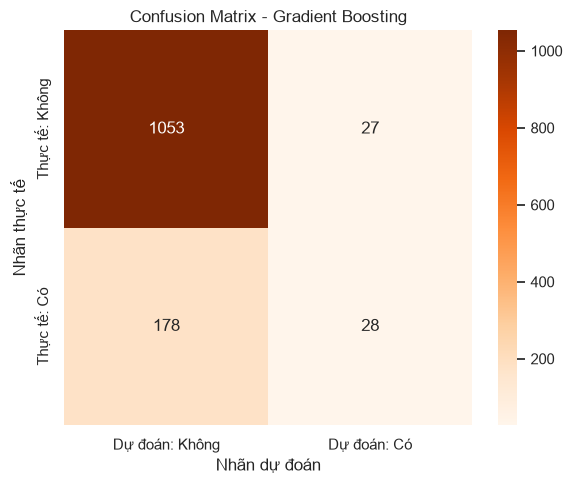

              precision    recall  f1-score   support

       Không       0.86      0.97      0.91      1080
          Có       0.51      0.14      0.21       206

    accuracy                           0.84      1286
   macro avg       0.68      0.56      0.56      1286
weighted avg       0.80      0.84      0.80      1286



In [70]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_gb = confusion_matrix(y_test, y_pred_gb, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Dự đoán: Không", "Dự đoán: Có"],
    yticklabels=["Thực tế: Không", "Thực tế: Có"]
)

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_gb,
    labels=[0, 1],
    target_names=["Không", "Có"],
    zero_division=0
))

### 4.5.8. Phân tích mức độ quan trọng của đặc trưng 

,Feature,Importance
8,Q23,0.1825
2,Q15,0.1607
7,Q22,0.1597
5,Q20,0.1565
9,Q27,0.1029
4,Q17,0.0861
3,Q16,0.0739
6,Q21,0.0413
0,Q1,0.0203
1,Q2,0.0160


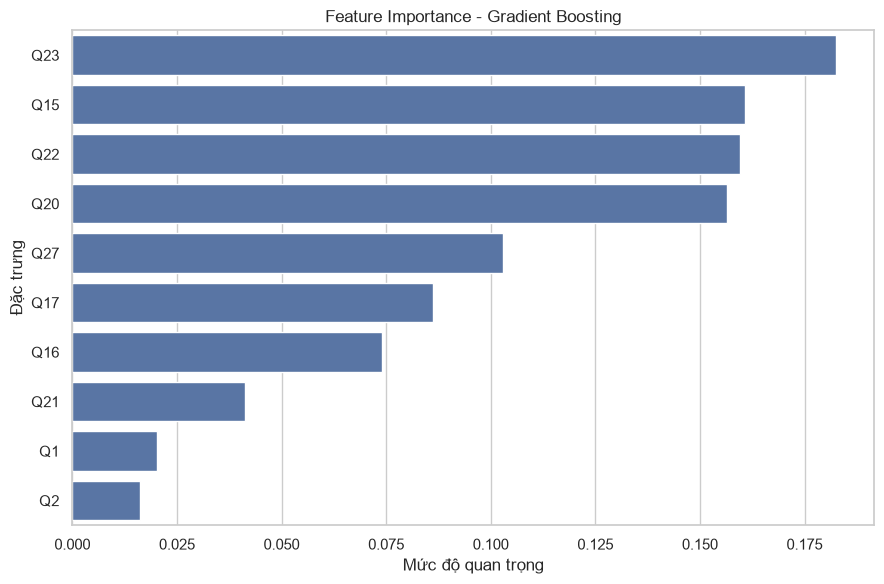

In [71]:
feature_importance_gb = pd.DataFrame({
    "Feature": input_columns,
    "Importance": gradient_boosting.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance_gb.round(4))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance_gb,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Gradient Boosting")
plt.xlabel("Mức độ quan trọng")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

### 4.5.9. Nhận xét và kết luận

Sau khi thực thi, điền kết quả thực tế:
- Gradient Boosting đạt Accuracy ..., Precision ..., Recall ... và F1-score ....
- Confusion Matrix cho thấy mô hình phát hiện được ... trường hợp Có và bỏ sót ... trường hợp.
- Các đặc trưng có mức quan trọng cao nhất là ..., ... và ....
- So sánh với Decision Tree và Random Forest để xác định liệu việc xây dựng các cây theo tuần tự có cải thiện khả năng phân loại hay không.

---
# PHẦN 5. XÂY DỰNG MÔ HÌNH DEEP LEARNING

### 5.1. Giới thiệu Neural Network (MLP)

Multilayer Perceptron (MLP) là mạng nơ-ron nhân tạo truyền thẳng, gồm lớp đầu vào, một hoặc nhiều lớp ẩn và lớp đầu ra. Mỗi nơ-ron nhận dữ liệu từ lớp trước, tính tổng có trọng số, cộng hệ số chệch rồi áp dụng hàm kích hoạt để tạo đầu ra.

Trong đề tài này, MLP được sử dụng để phân loại câu trả lời Q24 thành hai nhóm:
- 1: Có nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua.
- 0: Không nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua.
MLP có khả năng học các mối quan hệ phi tuyến giữa những đặc trưng khảo sát như tuổi, giới tính, tình trạng bị bắt nạt, cảm giác cô đơn, lo lắng và số lượng bạn thân.

###  5.2. Thiết kế kiến trúc và cấu hình MLPClassifier

Mô hình được thiết kế với hai lớp ẩn gồm 32 và 16 nơ-ron. Hàm kích hoạt ReLU giúp mô hình học các quan hệ phi tuyến; thuật toán tối ưu Adam cập nhật trọng số trong quá trình huấn luyện.

In [72]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

print(mlp_model)

MLPClassifier(alpha=0.001, batch_size=64, early_stopping=True,
              hidden_layer_sizes=(32, 16), max_iter=300, n_iter_no_change=15,
              random_state=42)


Ý nghĩa các tham số chính:
- hidden_layer_sizes=(32, 16):	Hai lớp ẩn, lần lượt có 32 và 16 nơ-ron
- activation="relu"	       :    Hàm kích hoạt ReLU
- solver="adam"	           :    Thuật toán tối ưu trọng số Adam
- alpha=0.001	               :    Hệ số điều chuẩn L2 để hạn chế trọng số quá lớn
- batch_size=64	           :    Kích thước lô mẫu trong mỗi lần cập nhật
- learning_rate_init=0.001   :    Tốc độ học ban đầu
- max_iter=300	           :    Số vòng lặp huấn luyện tối đa
- early_stopping=True	       :    Dừng sớm khi điểm trên tập validation không cải thiện đủ
- validation_fraction=0.1	   :    Dành 10% dữ liệu Train để kiểm tra trong quá trình huấn luyện
- random_state=42	           :    Giúp tái lập kết quả

### 5.3. Huấn luyện mô hình.

In [73]:
import warnings
from sklearn.exceptions import ConvergenceWarning

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)

    mlp_model.fit(X_train_processed, y_train)

    convergence_warnings = [
        str(w.message)
        for w in caught_warnings
        if issubclass(w.category, ConvergenceWarning)
    ]

print("Huấn luyện MLP hoàn tất.")
print("Số vòng lặp đã thực hiện:", mlp_model.n_iter_)
print("Hội tụ trước giới hạn:", mlp_model.n_iter_ < mlp_model.max_iter)

if convergence_warnings:
    print("Cảnh báo hội tụ:")
    for warning_message in convergence_warnings:
        print("-", warning_message)

Huấn luyện MLP hoàn tất.
Số vòng lặp đã thực hiện: 29
Hội tụ trước giới hạn: True


Biểu đồ hàm mất mát trong quá trình huấn luyện

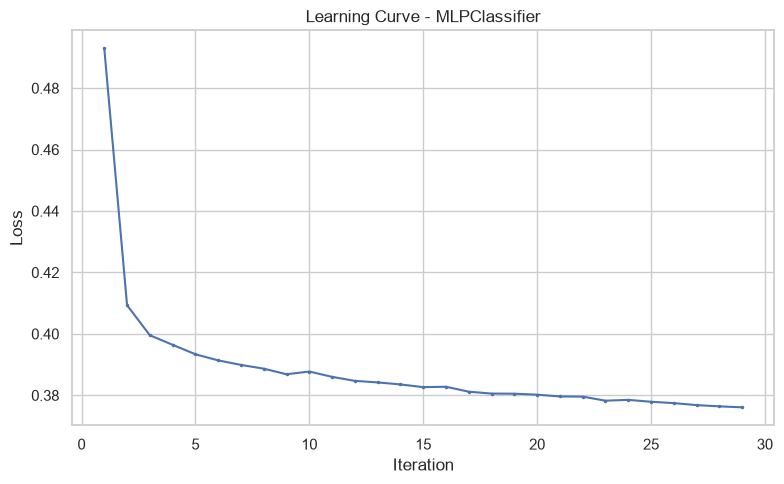

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(mlp_model.loss_curve_) + 1),
    mlp_model.loss_curve_,
    marker=".",
    markersize=3
)

plt.title("Learning Curve - MLPClassifier")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

###  5.4. Dự đoán trên tập Test.

In [75]:
y_pred_mlp = mlp_model.predict(X_test_processed)

# Xác suất dự đoán thuộc lớp Có (nhãn 1)
y_prob_mlp = mlp_model.predict_proba(X_test_processed)[:, 1]

print("10 nhãn thực tế đầu tiên:")
print(y_test.iloc[:10].to_list())

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred_mlp[:10])

print("\n10 xác suất dự đoán thuộc lớp Có:")
print(y_prob_mlp[:10].round(4))

10 nhãn thực tế đầu tiên:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

10 nhãn dự đoán đầu tiên:
[0 0 0 0 0 0 0 0 0 0]

10 xác suất dự đoán thuộc lớp Có:
[0.052  0.058  0.0676 0.1955 0.1841 0.0696 0.2192 0.0433 0.3175 0.0668]


###  5.5. Đánh giá các chỉ số 

In [76]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metrics_mlp = {
    "Accuracy": accuracy_score(y_test, y_pred_mlp),
    "Precision": precision_score(
        y_test, y_pred_mlp, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_mlp, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_pred_mlp, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_mlp)
}

results_mlp = pd.DataFrame(
    list(metrics_mlp.items()),
    columns=["Chỉ số", "Giá trị"]
)

display(results_mlp.round(4))

,Chỉ số,Giá trị
0,Accuracy,0.8429
1,Precision,0.5333
2,Recall,0.1553
3,F1-score,0.2406
4,ROC-AUC,0.7307


### 5.6. Phân tích Confusion Matrix

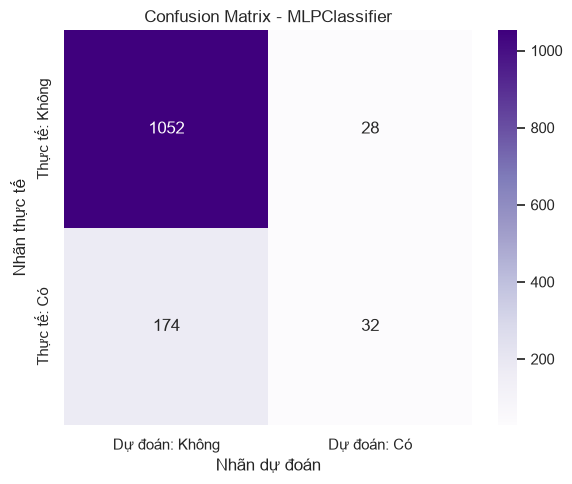

              precision    recall  f1-score   support

       Không       0.86      0.97      0.91      1080
          Có       0.53      0.16      0.24       206

    accuracy                           0.84      1286
   macro avg       0.70      0.56      0.58      1286
weighted avg       0.81      0.84      0.80      1286



In [77]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_mlp,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Dự đoán: Không", "Dự đoán: Có"],
    yticklabels=["Thực tế: Không", "Thực tế: Có"]
)

plt.title("Confusion Matrix - MLPClassifier")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_mlp,
    labels=[0, 1],
    target_names=["Không", "Có"],
    zero_division=0
))

### 5.7. Nhận xét kết quả.

Sau khi chạy notebook, sử dụng số liệu thực tế để hoàn thiện phần nhận xét. Không nên tự điền các giá trị khi chưa có kết quả.

Có thể trình bày theo mẫu:
- Hiệu quả tổng thể: MLPClassifier đạt Accuracy ..., Precision ..., Recall ..., F1-score ... và ROC-AUC ... trên tập Test.
- Khả năng phát hiện lớp Có: Confusion Matrix cho thấy mô hình phát hiện đúng ... trường hợp Có và bỏ sót ... trường hợp.
- Quá trình huấn luyện: Mô hình thực hiện ... vòng lặp; đường Loss có xu hướng ....
- Ưu điểm: MLP có khả năng học các quan hệ phi tuyến và kết hợp nhiều đặc trưng.
- Hạn chế: Mô hình có nhiều tham số cần tối ưu, nhạy với tiền xử lý và cấu hình; khả năng giải thích thường kém trực quan hơn Logistic Regression hoặc Decision Tree.

Kết luận: MLPClassifier bổ sung một mô hình mạng nơ-ron vào quá trình thực nghiệm. Kết quả cần được so sánh với Logistic Regression, Decision Tree, Random Forest và Gradient Boosting trên cùng tập Test. Không thể mặc định Deep Learning tốt hơn Machine Learning truyền thống chỉ vì kiến trúc phức tạp hơn.

---
# PHẦN 6. SO SÁNH 5 MÔ HÌNH

### 6.1. Tạo bảng tổng hợp kết quả.


In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting,
    "Neural Network (MLP)": mlp_model
}

comparison_results = []

for model_name, model in models.items():
    # Dự đoán nhãn trên cùng tập kiểm tra
    y_pred = model.predict(X_test_processed)

    # Xác suất thuộc lớp Có (Q24 = 1)
    class_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test_processed)[:, class_index]

    comparison_results.append({
        "Mô hình": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

# Sắp xếp theo F1-score của lớp Có
comparison_df = comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.7636,0.3478,0.5437,0.4242,0.7320
1,Logistic Regression,0.7068,0.2988,0.6165,0.4025,0.7281
2,Decision Tree,0.7162,0.2869,0.5194,0.3696,0.6790
3,Neural Network (MLP),0.8429,0.5333,0.1553,0.2406,0.7307
4,Gradient Boosting,0.8406,0.5091,0.1359,0.2146,0.7292


### 6.2. Vẽ biểu đồ so sánh Accuracy, Precision, Recall và F1-score.


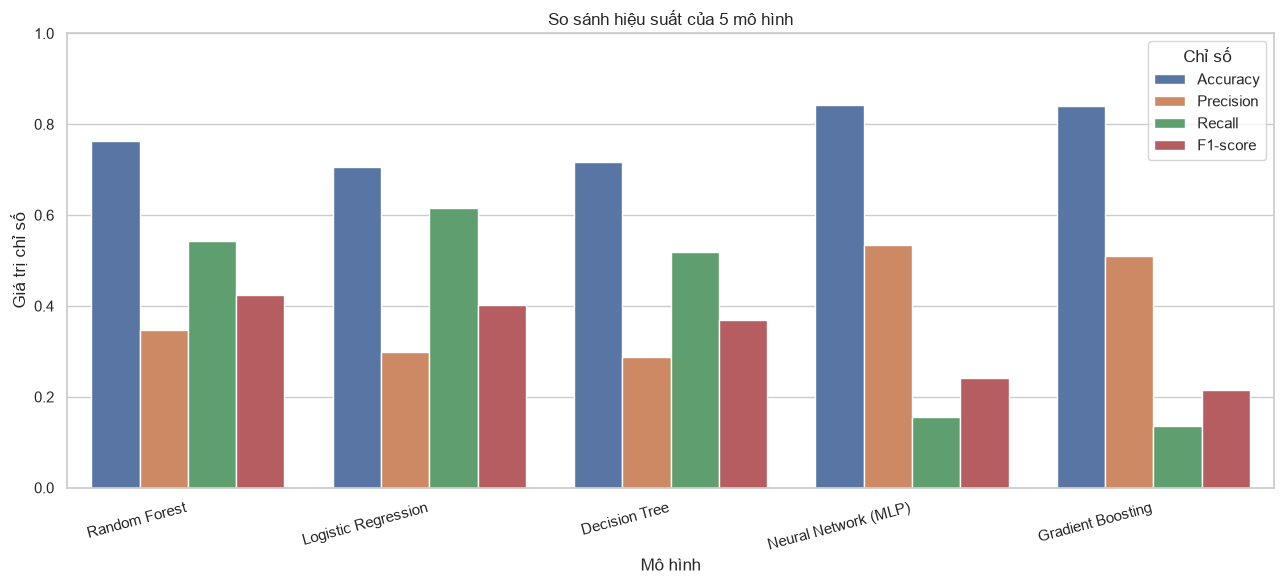

In [79]:
# 7.2. So sánh 4 chỉ số chính

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plot_df = comparison_df.melt(
    id_vars="Mô hình",
    value_vars=metrics,
    var_name="Chỉ số",
    value_name="Giá trị"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x="Mô hình",
    y="Giá trị",
    hue="Chỉ số"
)

plt.title("So sánh hiệu suất của 5 mô hình")
plt.xlabel("Mô hình")
plt.ylabel("Giá trị chỉ số")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Chỉ số")
plt.tight_layout()
plt.show()

Kết quả trên tập Test cho thấy Logistic Regression có Recall cao nhất (0,6165), còn Random Forest có F1-score cao nhất (0,4242). Decision Tree đạt Recall 0,5194 và F1-score 0,3696; Gradient Boosting đạt 0,1359 và 0,2146; Neural Network (MLP) đạt 0,1553 và 0,2406.

Các mô hình cần được so sánh đồng thời theo Precision, Recall và F1-score. Accuracy cao không đảm bảo khả năng phát hiện tốt nhóm Có khi dữ liệu mất cân bằng.

### 6.3. So sánh khả năng phát hiện nhóm Có.


In [80]:
positive_class_results = comparison_df[
    ["Mô hình", "Precision", "Recall", "F1-score"]
].copy()

positive_class_results = positive_class_results.sort_values(
    "Recall",
    ascending=False
).reset_index(drop=True)

display(positive_class_results.round(4))

,Mô hình,Precision,Recall,F1-score
0,Logistic Regression,0.2988,0.6165,0.4025
1,Random Forest,0.3478,0.5437,0.4242
2,Decision Tree,0.2869,0.5194,0.3696
3,Neural Network (MLP),0.5333,0.1553,0.2406
4,Gradient Boosting,0.5091,0.1359,0.2146


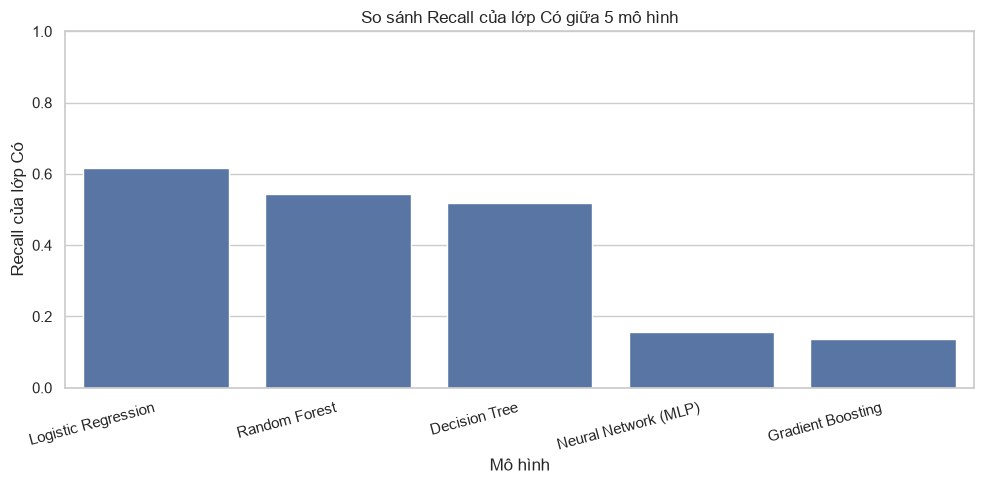

In [81]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=positive_class_results,
    x="Mô hình",
    y="Recall"
)

plt.title("So sánh Recall của lớp Có giữa 5 mô hình")
plt.xlabel("Mô hình")
plt.ylabel("Recall của lớp Có")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [82]:
# Số lượng TP và FN của từng mô hình
detection_results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Ma trận có thứ tự:
    # [[TN, FP],
    #  [FN, TP]]
    tn, fp, fn, tp = cm.ravel()

    detection_results.append({
        "Mô hình": model_name,
        "TP - Phát hiện đúng Có": tp,
        "FN - Bỏ sót Có": fn,
        "FP - Dự đoán Có sai": fp,
        "TN - Phát hiện đúng Không": tn
    })

detection_df = pd.DataFrame(detection_results)

display(detection_df)

,Mô hình,TP - Phát hiện đúng Có,FN - Bỏ sót Có,FP - Dự đoán Có sai,TN - Phát hiện đúng Không
0,Logistic Regression,127,79,298,782
1,Decision Tree,107,99,266,814
2,Random Forest,112,94,210,870
3,Gradient Boosting,28,178,27,1053
4,Neural Network (MLP),32,174,28,1052


Theo Confusion Matrix trên tập Test, Logistic Regression phát hiện đúng 127 trường hợp Có và bỏ sót 79 trường hợp, nhưng có 298 dự đoán Có sai. Random Forest phát hiện đúng 112 trường hợp Có, bỏ sót 94 trường hợp và có 210 dự đoán Có sai. Vì vậy, Logistic Regression phát hiện nhiều trường hợp Có hơn, còn Random Forest giảm số dự đoán Có sai và có F1-score cao hơn.

Gradient Boosting và MLP lần lượt phát hiện đúng 28 và 32 trường hợp Có, đồng thời bỏ sót 178 và 174 trường hợp. Nếu ưu tiên giảm bỏ sót, cần chú ý Recall và FN; đồng thời xem xét FP để đánh giá hệ quả của các dự đoán dương tính sai.

### 6.4. Xác định mô hình phù hợp với mục tiêu nghiên cứu.

Qua kết quả đánh giá năm mô hình, Logistic Regression có Recall cao nhất (0,6165), nên phù hợp hơn khi mục tiêu ưu tiên hạn chế bỏ sót nhóm Có. Random Forest có F1-score cao nhất (0,4242), đồng thời có ít dự đoán Có sai hơn Logistic Regression trong Confusion Matrix; đây là lựa chọn cân bằng hơn giữa Precision và Recall. Việc lựa chọn cuối cùng phụ thuộc vào mục tiêu nghiên cứu và chi phí tương đối của FN, FP.

Các mô hình chỉ hỗ trợ phân tích dữ liệu khảo sát, không phải công cụ chẩn đoán hoặc đánh giá nguy cơ tự tử của từng cá nhân.

---
# PHẦN 7. KẾT LUẬN

## 7.1. Tổng kết các phát hiện từ EDA.


Thông qua quá trình phân tích khám phá dữ liệu (EDA), nghiên cứu khảo sát đặc điểm nhân khẩu học cùng các yếu tố hành vi và trạng thái tâm lý của học sinh tại Morocco. Biến mục tiêu Q24 phản ánh việc học sinh có từng nghiêm túc nghĩ đến tự tử trong 12 tháng qua hay không.

Trong 6.427 câu trả lời Q24 hợp lệ, có 1.031 trường hợp Có (16,04%) và 5.396 trường hợp Không (83,96%). Có 318 dòng thiếu hoặc không thuộc mã 1/2, chiếm 4,71% tổng số 6.745 dòng. Các giá trị thiếu hoặc mã không hợp lệ không được tự động gán thành câu trả lời Không.

Các biến đầu vào được lựa chọn gồm độ tuổi, giới tính, tần suất bị tấn công thể chất, tham gia đánh nhau, bị thương nghiêm trọng, bị bắt nạt, cảm giác cô đơn, lo lắng ảnh hưởng đến giấc ngủ và số lượng bạn thân. Các mã và mô tả câu hỏi được đối chiếu với tài liệu `QuyUocMorocco.docx`.

Kết quả EDA giúp nhận diện đặc điểm phân bố dữ liệu, tình trạng thiếu dữ liệu và sự mất cân bằng giữa hai nhóm Có và Không. Tuy nhiên, các mối liên hệ quan sát được không chứng minh quan hệ nhân quả.

## 7.2. Tổng kết kết quả các mô hình.


Nghiên cứu đã xây dựng và đánh giá năm mô hình phân loại gồm Logistic Regression, Decision Tree, Random Forest, Gradient Boosting và Neural Network (MLP). Trên tập Test, Logistic Regression đạt Recall cao nhất (0,6165), còn Random Forest đạt F1-score cao nhất (0,4242). Decision Tree đạt F1-score 0,3696; Gradient Boosting và MLP lần lượt đạt 0,2146 và 0,2406.

Nếu mục tiêu là giảm số trường hợp Có bị bỏ sót, Logistic Regression là lựa chọn đáng cân nhắc; nếu ưu tiên cân bằng Precision và Recall, Random Forest có kết quả tốt hơn theo F1-score. Cần diễn giải các kết quả trong bối cảnh dữ liệu mất cân bằng và không xem mô hình là công cụ chẩn đoán.

## 7.3. Hạn chế của dữ liệu và phương pháp.


Nghiên cứu còn một số hạn chế cần được xem xét khi diễn giải kết quả.

Thứ nhất, Q24 có 318 dòng thiếu hoặc không thuộc mã 1/2 trong tổng số 6.745 dòng. Phần tiền xử lý chỉ giữ 6.427 trường hợp có nhãn hợp lệ; các kết quả mô hình vì vậy chỉ phản ánh những người đã trả lời Q24 theo mã hợp lệ và có thể chịu ảnh hưởng bởi sai lệch do thiếu dữ liệu.

Thứ hai, dữ liệu có sự mất cân bằng giữa nhóm Có (16,04%) và nhóm Không (83,96%). Điều này có thể khiến Accuracy không phản ánh đầy đủ khả năng phát hiện nhóm Có. Do đó, nghiên cứu cần xem xét đồng thời Precision, Recall, F1-score và ma trận nhầm lẫn.

Thứ ba, các câu trả lời khảo sát có thể chịu ảnh hưởng từ khả năng ghi nhớ, cách hiểu câu hỏi và mức độ sẵn sàng chia sẻ thông tin của người tham gia. Những yếu tố này có thể làm phát sinh sai lệch trong dữ liệu.

Thứ tư, các mô hình chỉ sử dụng mười biến đầu vào đã lựa chọn. Những yếu tố khác không có trong bộ biến này có thể cũng liên quan đến biến mục tiêu nhưng chưa được xem xét.

Cuối cùng, kết quả mô hình phản ánh khả năng phân loại trên tập dữ liệu khảo sát hiện có, không chứng minh quan hệ nhân quả và không thể thay thế đánh giá chuyên môn về sức khỏe tâm thần. Khả năng khái quát hóa sang nhóm học sinh hoặc quốc gia khác cũng cần được kiểm chứng thêm.